# HSF CMS Higgs-to-WW: exploratory classification

**Om and Rishabh**

We are exploring whether kinematic features in four ROOT files can distinguish a Higgs-labelled sample from files labelled DY, Top and WW. We inspect the data, check feature calculations, compare candidate classifiers and study their validation scores. The names provide provisional labels only; they do not verify the CMS processes or establish a physics result.


## Setup

Use Python 3.14 with the packages in `requirements_mentor_workflow.txt`. Put the four `*-train.root` files in `new_datasets/` and run from a fresh kernel. Only these training files are read; values from `Higgs-test.root` are not used.


In [1]:
from __future__ import annotations
import csv, hashlib, json, math, platform, sys, time
from pathlib import Path
from itertools import combinations

import awkward as ak
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import scipy
from scipy.spatial import cKDTree
from scipy.stats import chisquare, kstest, ks_2samp
import sklearn
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
                             confusion_matrix, f1_score, precision_score, recall_score,
                             roc_auc_score, roc_curve, precision_recall_curve)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight
from threadpoolctl import threadpool_limits
import uproot
from IPython.display import display, Image

SEED = 20261015
BOOTSTRAP_SEED = 20261016
CLASSES = ["DY", "Higgs", "Top", "WW"]
TRAIN_FILES = {name: f"{name}-train.root" for name in CLASSES}
ROOT_BRANCHES = [
    "Jet1_eta", "Jet1_phi", "Jet1_pt", "Jet2_eta", "Jet2_phi", "Jet2_pt",
    "Lepton1_eta", "Lepton1_phi", "Lepton1_pt", "Lepton2_eta", "Lepton2_phi", "Lepton2_pt",
    "PuppiMET_phi", "PuppiMET_pt", "dphill", "jet_cat", "mjj", "mll", "mth", "mtw2", "njet", "ptll",
]

def find_repo(start=Path.cwd()):
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / "new_datasets").is_dir() and (candidate / "outputs").is_dir():
            return candidate
    raise FileNotFoundError("Could not find repository root containing new_datasets/ and outputs/")

REPO = find_repo()
DATA_DIR = REPO / "new_datasets"
OUT_DIR = REPO / "outputs/mentor_workflow/phase4_20261015_om_rishabh_v1"
OUT_DIR.mkdir(parents=True, exist_ok=True)
assert set(TRAIN_FILES.values()) == {"DY-train.root", "Higgs-train.root", "Top-train.root", "WW-train.root"}
assert "Higgs-test.root" not in TRAIN_FILES.values()
assert not (DATA_DIR / "Higgs-test.root").resolve() in { (DATA_DIR / f).resolve() for f in TRAIN_FILES.values() }
print({"python": sys.version.split()[0], "numpy": np.__version__, "scipy": scipy.__version__,
       "scikit_learn": sklearn.__version__, "uproot": uproot.__version__, "awkward": ak.__version__,
       "matplotlib": matplotlib.__version__, "seed": SEED, "repo": str(REPO), "output": str(OUT_DIR)})

{'python': '3.14.8', 'numpy': '2.5.4', 'scipy': '1.18.1', 'scikit_learn': '1.9.1', 'uproot': '5.7.7', 'awkward': '2.14.0', 'matplotlib': '3.11.2', 'seed': 20261015, 'repo': '/Users/falcon/Documents/docs/hsf-india-bvcoe-2026', 'output': '/Users/falcon/Documents/docs/hsf-india-bvcoe-2026/outputs/mentor_workflow/phase4_20261015_om_rishabh_v1'}


## 1. What is in the files?

We inspect the ROOT tree, branch types, entry counts and input hashes, then read the training files in chunks. This describes the reduced files as stored; it does not establish their CMS provenance or selection history.


In [2]:
EXPECTED_INPUT_SHA256 = {
    "DY-train.root": "65d8e6ef0da05be440e6d38288ef479a9dc9055b9340fabf679a7b54f5367948",
    "Higgs-train.root": "efcda212fba7ce344787840f7282a0fb37495861bbc71f1c74ca219c78041195",
    "Top-train.root": "30beb02050e2c007792bd7313e69fcaba42c564da08db6e3f8b06687f17f4841",
    "WW-train.root": "3388cb9207ac8fdc3dd3a964522a8047f00b0e5ee58eedfa7c5560d184e494c4",
}
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

inventory = []
arrays_by_class = {}
for label, filename in TRAIN_FILES.items():
    path = DATA_DIR / filename
    digest = sha256_file(path)
    assert digest == EXPECTED_INPUT_SHA256[filename], f"Input hash changed: {filename}"
    with uproot.open(path) as root_file:
        tree = root_file["Events"]
        branches = list(tree.keys())
        typenames = tree.typenames()
        assert set(branches) == set(ROOT_BRANCHES), f"Unexpected schema in {filename}"
        inventory.append({"filename": filename, "filename_label": label, "object": "Events",
                          "class": tree.classname, "entries": int(tree.num_entries),
                          "branch_count": len(branches), "typenames": typenames,
                          "sha256": digest, "bytes": path.stat().st_size})
        pieces = []
        for chunk in tree.iterate(expressions=ROOT_BRANCHES, step_size="25 MB", library="np"):
            pieces.append(np.column_stack([chunk[name] for name in ROOT_BRANCHES]))
        arrays_by_class[label] = np.concatenate(pieces, axis=0).astype(np.float32, copy=False)
    print(label, filename, inventory[-1]["entries"], "rows loaded", arrays_by_class[label].shape)

assert len({tuple(sorted(row["typenames"].items())) for row in inventory}) == 1
assert all(np.isfinite(arrays_by_class[label]).all() for label in CLASSES)
with (OUT_DIR / "input_inventory.json").open("w") as f:
    json.dump({"files": inventory, "test_file_event_values_read": False,
               "labels_are_filename_derived_only": True}, f, indent=2)
print("ROOT schema/types:", inventory[0]["typenames"])
print("Counts:", {r["filename_label"]: r["entries"] for r in inventory},
      "total:", sum(r["entries"] for r in inventory))

DY DY-train.root 39103 rows loaded (39103, 22)
Higgs Higgs-train.root 21584 rows loaded (21584, 22)


Top Top-train.root 20453 rows loaded (20453, 22)
WW WW-train.root 112816 rows loaded (112816, 22)
ROOT schema/types: {'Jet1_eta': 'float', 'Jet1_phi': 'float', 'Jet1_pt': 'float', 'Jet2_eta': 'float', 'Jet2_phi': 'float', 'Jet2_pt': 'float', 'Lepton1_eta': 'float', 'Lepton1_phi': 'float', 'Lepton1_pt': 'float', 'Lepton2_eta': 'float', 'Lepton2_phi': 'float', 'Lepton2_pt': 'float', 'PuppiMET_phi': 'float', 'PuppiMET_pt': 'float', 'dphill': 'float', 'jet_cat': 'std::int32_t', 'mjj': 'float', 'mll': 'float', 'mth': 'float', 'mtw2': 'float', 'njet': 'std::int32_t', 'ptll': 'float'}
Counts: {'DY': 39103, 'Higgs': 21584, 'Top': 20453, 'WW': 112816} total: 193956


## 2. Check the feature calculations

We recompute dilepton and transverse quantities from the stored lepton and MET coordinates. Since the files do not identify which pT-ordered lepton is the electron, the dilepton-mass check tests both electron/muon assignments and a massless approximation. We also compare `mjj` with a massless-jet estimate; missing jet masses limit that check. These are consistency checks on the reduced columns, not a substitute for source-event validation.


In [3]:
IDX = {name: i for i, name in enumerate(ROOT_BRANCHES)}
def wrap_phi(value):
    return (np.asarray(value, dtype=np.float64) + np.pi) % (2 * np.pi) - np.pi
def quantile_summary(values):
    values = np.asarray(values, dtype=np.float64)
    return {"median": float(np.quantile(values, .5)), "q95": float(np.quantile(values, .95)),
            "q99": float(np.quantile(values, .99)), "max": float(np.max(values))}
def mass_from_pt_eta_phi(pt1, eta1, phi1, m1, pt2, eta2, phi2, m2):
    def components(pt, eta, phi, mass):
        px, py, pz = pt*np.cos(phi), pt*np.sin(phi), pt*np.sinh(eta)
        energy = np.sqrt((pt*np.cosh(eta))**2 + mass**2)
        return energy, px, py, pz
    a = components(pt1, eta1, phi1, m1); b = components(pt2, eta2, phi2, m2)
    m2pair = (a[0]+b[0])**2 - (a[1]+b[1])**2 - (a[2]+b[2])**2 - (a[3]+b[3])**2
    return np.sqrt(np.maximum(m2pair, 0.0))

M_E_GEV, M_MU_GEV = 0.00051099895000, 0.1056583755
feature_validation = []
formula_values = {}
for label, matrix in arrays_by_class.items():
    a = {name: matrix[:, IDX[name]].astype(np.float64) for name in ROOT_BRANCHES}
    mll_e_mu = mass_from_pt_eta_phi(a["Lepton1_pt"],a["Lepton1_eta"],a["Lepton1_phi"],M_E_GEV,
                                    a["Lepton2_pt"],a["Lepton2_eta"],a["Lepton2_phi"],M_MU_GEV)
    mll_mu_e = mass_from_pt_eta_phi(a["Lepton1_pt"],a["Lepton1_eta"],a["Lepton1_phi"],M_MU_GEV,
                                    a["Lepton2_pt"],a["Lepton2_eta"],a["Lepton2_phi"],M_E_GEV)
    mll_massless = mass_from_pt_eta_phi(a["Lepton1_pt"],a["Lepton1_eta"],a["Lepton1_phi"],0.,
                                        a["Lepton2_pt"],a["Lepton2_eta"],a["Lepton2_phi"],0.)
    dphi = wrap_phi(a["Lepton1_phi"] - a["Lepton2_phi"])
    pxll = a["Lepton1_pt"]*np.cos(a["Lepton1_phi"]) + a["Lepton2_pt"]*np.cos(a["Lepton2_phi"])
    pyll = a["Lepton1_pt"]*np.sin(a["Lepton1_phi"]) + a["Lepton2_pt"]*np.sin(a["Lepton2_phi"])
    ptll = np.hypot(pxll, pyll); phi_ll = np.arctan2(pyll, pxll)
    mth = np.sqrt(np.maximum(2*ptll*a["PuppiMET_pt"]*(1-np.cos(wrap_phi(phi_ll-a["PuppiMET_phi"]))),0.))
    mtw2 = np.sqrt(np.maximum(2*a["Lepton2_pt"]*a["PuppiMET_pt"]*(1-np.cos(wrap_phi(a["Lepton2_phi"]-a["PuppiMET_phi"]))),0.))
    formula_values[label] = {"mll_e_mu":mll_e_mu,"mll_mu_e":mll_mu_e,"mll_massless":mll_massless,
                             "dphill":dphi,"ptll":ptll,"mth":mth,"mtw2":mtw2}
    jetmask=(a["njet"]>=2)&(a["Jet1_pt"]>0)&(a["Jet2_pt"]>0)
    mjj_massless=np.sqrt(np.maximum(2*a["Jet1_pt"][jetmask]*a["Jet2_pt"][jetmask]*
        (np.cosh(a["Jet1_eta"][jetmask]-a["Jet2_eta"][jetmask])-
         np.cos(wrap_phi(a["Jet1_phi"][jetmask]-a["Jet2_phi"][jetmask]))),0.))
    mjj_delta=np.abs(mjj_massless-a["mjj"][jetmask])
    feature_validation.append({"sample":label,"feature_or_hypothesis":"mjj_massless_jet_approx","n":int(jetmask.sum()),
        "absolute_median":float(np.median(mjj_delta)),"absolute_q95":float(np.quantile(mjj_delta,.95)),
        "absolute_q99":float(np.quantile(mjj_delta,.99)),"absolute_max":float(np.max(mjj_delta)),
        "relative_median":float(np.median(mjj_delta/np.maximum(np.abs(a["mjj"][jetmask]),1e-12)))})
    for feature, calculated in [("mll_e_mu",mll_e_mu),("mll_mu_e",mll_mu_e),("mll_massless",mll_massless),
                                ("dphill",dphi),("ptll",ptll),("mth",mth),("mtw2",mtw2)]:
        stored_name = "mll" if feature.startswith("mll_") else feature
        stored = a[stored_name]
        delta = np.abs(calculated-stored)
        feature_validation.append({"sample":label,"feature_or_hypothesis":feature,"n":len(delta),
                                   "absolute_median":float(np.median(delta)),"absolute_q95":float(np.quantile(delta,.95)),
                                   "absolute_q99":float(np.quantile(delta,.99)),"absolute_max":float(np.max(delta)),
                                   "relative_median":float(np.median(delta/np.maximum(np.abs(stored),1e-12)))})

with (OUT_DIR/"feature_validation.csv").open("w",newline="") as f:
    w=csv.DictWriter(f,fieldnames=list(feature_validation[0]));w.writeheader();w.writerows(feature_validation)
for row in feature_validation: print(row["sample"],row["feature_or_hypothesis"],row["absolute_median"],row["absolute_q95"],row["absolute_max"])

DY mjj_massless_jet_approx 1.77445958441551 5.681044269523791 22.775007086558958
DY mll_e_mu 3.7011072656412125e-05 0.00039702103585668194 0.13961672054763663
DY mll_mu_e 4.520662452023316e-05 0.0005060218921961737 0.2369607372734669
DY mll_massless 0.000216630752902347 0.0006661036515325236 0.2575749291649555
DY dphill 6.357301884918343e-08 2.384185791015625e-07 2.5331974029541016e-07
DY ptll 5.822760300588925e-07 2.199058269169996e-06 3.302183137066095e-05
DY mth 1.4125700085187987e-06 8.553912287467831e-06 0.0062308608303990876
DY mtw2 1.0789343107830973e-06 6.299618705440935e-06 0.002495610935883734
Higgs mjj_massless_jet_approx 2.095131521760109 6.934060716030261 27.593250425281497
Higgs mll_e_mu 6.686460033922259e-05 0.0008037356501745305 0.015511752579964622
Higgs mll_mu_e 7.456460252086572e-05 0.0009784126412832866 0.0216495959573626
Higgs mll_massless 0.0003485881461617879 0.0015124138300453842 0.03479682828185682
Higgs dphill 0.0 2.384185791015625e-07 2.384185791015625e-07
Hi

## 3. Distributions and data checks

The plots show unit-area shapes, so they compare feature distributions without implying event yields. We check the stored selection-related values and compare class distributions with KS tests. These tests are descriptive and do not account for unknown shared event or production structure.


DY L1 min 25.000524520874023 L2 min 10.000848770141602 fraction passing 25/13 0.9117714753343733 no-jet fraction 0.7840830626806128
Higgs L1 min 25.00345230102539 L2 min 10.00039291381836 fraction passing 25/13 0.9267976278724982 no-jet fraction 0.5981745737583395


Top L1 min 25.001914978027344 L2 min 10.01343822479248 fraction passing 25/13 0.9692465652960446 no-jet fraction 0.1373392656334034


WW L1 min 25.001625061035156 L2 min 10.000905990600586 fraction passing 25/13 0.9789214295844562 no-jet fraction 0.6457417387604595


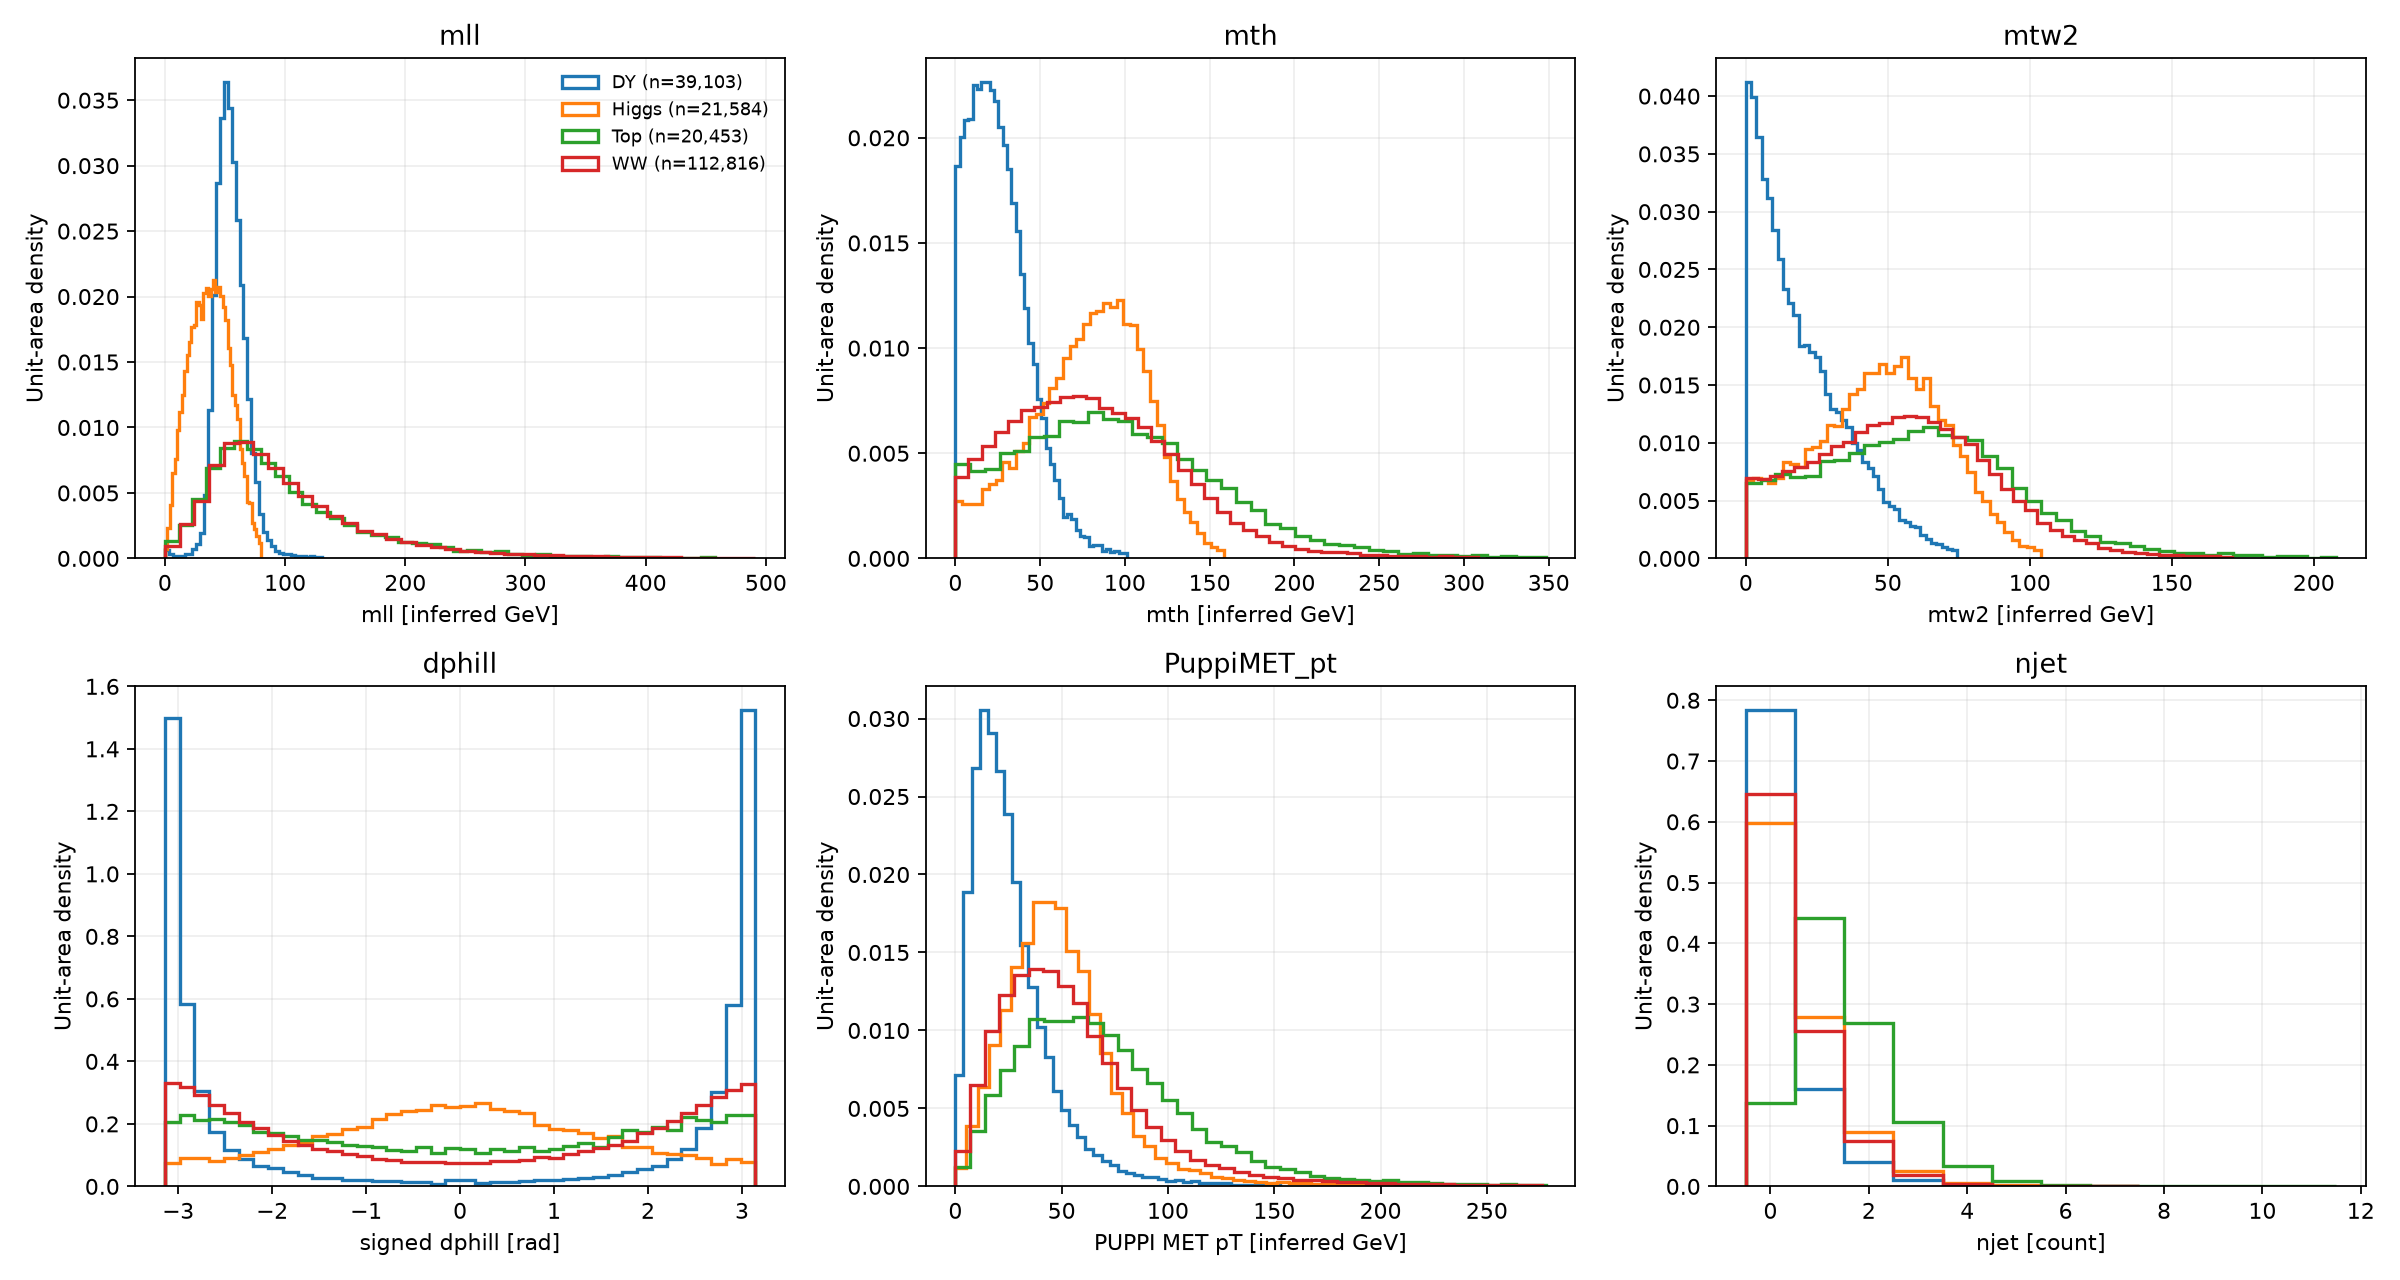

Saved training-only distribution diagnostics and plots.


In [4]:
distribution_rows = []
for label, matrix in arrays_by_class.items():
    a={name:matrix[:,IDX[name]].astype(float) for name in ROOT_BRANCHES}
    for name in ["mll","mth","mtw2","dphill","PuppiMET_pt","njet","jet_cat","Jet1_pt","Jet2_pt"]:
        x=a[name]
        distribution_rows.append({"kind":"class_distribution","sample":label,"feature":name,"n":len(x),
            "mean":float(np.mean(x)),"std":float(np.std(x)),"min":float(np.min(x)),"q01":float(np.quantile(x,.01)),
            "q25":float(np.quantile(x,.25)),"median":float(np.median(x)),"q75":float(np.quantile(x,.75)),
            "q99":float(np.quantile(x,.99)),"max":float(np.max(x)),"zero_fraction":float(np.mean(x==0))})
    assert not np.any(matrix == -999)
    assert np.all(a["Lepton1_pt"] > 25)
    assert np.all(np.abs(a["Lepton1_eta"]) < 2.5) and np.all(np.abs(a["Lepton2_eta"]) < 2.5)
    assert np.all(a["jet_cat"] == np.minimum(a["njet"],2))
    assert np.all((a["Jet1_pt"]==0) == (a["njet"]==0))
    assert np.all((a["Jet2_pt"]==0) == (a["njet"]<2))
    p2=np.mean((a["Lepton1_pt"]>25)&(a["Lepton2_pt"]>13))
    print(label,"L1 min",a["Lepton1_pt"].min(),"L2 min",a["Lepton2_pt"].min(),
          "fraction passing 25/13",p2,"no-jet fraction",np.mean(a["njet"]==0))
    for name in ["Lepton1_phi","Lepton2_phi","PuppiMET_phi","Jet1_phi","Jet2_phi"]:
        keep=np.ones(len(matrix),dtype=bool)
        if name=="Jet1_phi": keep=a["Jet1_pt"]>0
        if name=="Jet2_phi": keep=a["Jet2_pt"]>0
        angles=wrap_phi(a[name][keep]); u=(angles+np.pi)/(2*np.pi)
        ks=kstest(u,"uniform",method="auto")
        counts,_=np.histogram(u,bins=np.linspace(0,1,21)); chi=chisquare(counts,np.full(20,len(u)/20))
        distribution_rows.append({"kind":"phi_uniformity","sample":label,"feature":name,"n":len(u),
            "ks_D":float(ks.statistic),"ks_p":float(ks.pvalue),"chi2_20bin":float(chi.statistic),"chi2_20bin_p":float(chi.pvalue)})

pair_rows=[]
for ca,cb in combinations(CLASSES,2):
    for feature in ["mll","mth","mtw2","dphill","PuppiMET_pt","njet","jet_cat","Jet1_pt","Jet1_eta","Jet2_pt"]:
        xa=arrays_by_class[ca][:,IDX[feature]].astype(float); xb=arrays_by_class[cb][:,IDX[feature]].astype(float)
        test=ks_2samp(xa,xb,method="auto")
        scale=np.sqrt((np.var(xa)+np.var(xb))/2)
        pair_rows.append({"kind":"class_pair_ks","sample":ca,"comparison_sample":cb,"feature":feature,
            "n":len(xa),"comparison_n":len(xb),"ks_statistic":float(test.statistic),"pvalue_unadjusted":float(test.pvalue),
            "standardized_mean_difference":float((np.mean(xa)-np.mean(xb))/scale) if scale else 0.0})
pvals=np.asarray([r["pvalue_unadjusted"] for r in pair_rows]); order=np.argsort(pvals); qvals=np.empty(len(pvals)); running=1.0
for rank in range(len(order)-1,-1,-1):
    idx=order[rank]; running=min(running,pvals[idx]*len(order)/(rank+1)); qvals[idx]=running
for row,qvalue in zip(pair_rows,qvals): row["pvalue_BH_qvalue_all_pairwise_feature_tests"]=float(qvalue)
distribution_rows.extend(pair_rows)

plot_features=[("mll","mll [inferred GeV]"),("mth","mth [inferred GeV]"),("mtw2","mtw2 [inferred GeV]"),
               ("dphill","signed dphill [rad]"),("PuppiMET_pt","PUPPI MET pT [inferred GeV]"),("njet","njet [count]")]
fig,axes=plt.subplots(2,3,figsize=(15,8))
for ax,(name,label) in zip(axes.flat,plot_features):
    for cls in CLASSES:
        x=arrays_by_class[cls][:,IDX[name]].astype(float)
        if name in {"mll","mth","mtw2","PuppiMET_pt"}:
            xmax=np.quantile(x,.995); bins=np.linspace(0,xmax,41)
        elif name=="dphill": bins=np.linspace(-np.pi,np.pi,41)
        else: bins=np.arange(-.5,arrays_by_class[cls][:,IDX[name]].max()+1.5,1)
        ax.hist(x,bins=bins,density=True,histtype="step",linewidth=1.5,label=f"{cls} (n={len(x):,})")
    ax.set(xlabel=label,ylabel="Unit-area density",title=name);ax.grid(alpha=.2)
axes[0,0].legend(frameon=False,fontsize=8);fig.tight_layout()
fig.savefig(OUT_DIR/"training_feature_shapes.png",dpi=160);display(Image(filename=str(OUT_DIR/"training_feature_shapes.png")));plt.close(fig)

with (OUT_DIR/"distribution_diagnostics.csv").open("w",newline="") as f:
    cols=list(dict.fromkeys(k for row in distribution_rows for k in row))
    w=csv.DictWriter(f,fieldnames=cols);w.writeheader();w.writerows(distribution_rows)
print("Saved training-only distribution diagnostics and plots.")

## 4. Similarity to the canonical samples

When the canonical feature tables are available locally, we compare training rows using eight kinematic coordinates. Angles are wrapped before matching. A match means the stored features are close; it does not establish event identity. If those optional files are absent, this section reports that the comparison was skipped.


In [5]:
TOLS=np.array([1e-3,1e-3,2e-5,2e-5,2e-5,2e-5,2e-5,1e-3],float)
def normalized_fingerprints(values):
    values=np.asarray(values,dtype=np.float64).copy()
    values[:,4]=wrap_phi(values[:,4]);values[:,5]=wrap_phi(values[:,5]);values[:,6]=wrap_phi(values[:,6])
    return values.astype(np.float32)
def canonical_training_features(dataset_dir):
    ledger=[]
    with (dataset_dir/"event_ledger.csv").open(newline="") as f:
        for row in csv.DictReader(f):
            if row["split"]=="train":
                ledger.append({"i":int(row["output_row"]),"process":row["process_label"],
                    "ept":float(row["electron_pt_GeV"]),"eeta":float(row["electron_eta"]),"ephi":float(row["electron_phi_rad"]),
                    "mpt":float(row["muon_pt_GeV"]),"meta":float(row["muon_eta"]),"mphi":float(row["muon_phi_rad"])})
    byrow={r["i"]:r for r in ledger}; core={}; optional={}
    for filename,destination in [("features.csv",core),("optional_features.csv",optional)]:
        with (dataset_dir/filename).open(newline="") as f:
            for i,row in enumerate(csv.DictReader(f)):
                if i in byrow: destination[i]=row
    assert len(byrow)==len(core)==len(optional)
    grouped={}
    for i,l in byrow.items():
        if l["ept"]>=l["mpt"]: lead=(l["ept"],l["eeta"],l["ephi"]);sub=(l["mpt"],l["meta"],l["mphi"])
        else: lead=(l["mpt"],l["meta"],l["mphi"]);sub=(l["ept"],l["eeta"],l["ephi"])
        row=[float(core[i]["pt_lead_GeV"]),float(core[i]["pt_sublead_GeV"]),lead[1],sub[1],lead[2],sub[2],
             float(optional[i]["dphill_signed_rad"]),float(core[i]["PuppiMET_pt_GeV"])]
        grouped.setdefault(l["process"],[]).append(row)
    return {name:normalized_fingerprints(rows) for name,rows in grouped.items()},len(ledger)

canonical_sets={}
canonical_names=["canonical_pilot_1000_per_process_20261015_v1",
                 "canonical_expanded_10000_per_process_20261015_v1"]
canonical_paths=[REPO/"outputs/canonical_samples"/name for name in canonical_names]
available_paths=[p for p in canonical_paths if all((p/f).is_file() for f in
                   ["event_ledger.csv","features.csv","optional_features.csv"])]
match_rows=[]
if available_paths:
    for path in available_paths:
        canonical_sets[path.name],n=canonical_training_features(path)
        print(path.name,"training ledger rows",n)
    for mentor_label,matrix in arrays_by_class.items():
        mentor=normalized_fingerprints(np.column_stack([matrix[:,IDX[n]] for n in
            ["Lepton1_pt","Lepton2_pt","Lepton1_eta","Lepton2_eta","Lepton1_phi","Lepton2_phi","dphill","PuppiMET_pt"]]))
        exact_key=np.ascontiguousarray(mentor).view(np.dtype((np.void,mentor.dtype.itemsize*mentor.shape[1]))).ravel()
        for dataset,groups in canonical_sets.items():
            for process,canonical in groups.items():
                canon_key=np.ascontiguousarray(canonical).view(np.dtype((np.void,canonical.dtype.itemsize*canonical.shape[1]))).ravel()
                keyset=set(canon_key.tolist())
                exact=sum(key in keyset for key in exact_key.tolist())
                tree=cKDTree(canonical.astype(float)/TOLS)
                distance,_=tree.query(mentor.astype(float)/TOLS,k=1,p=np.inf,distance_upper_bound=1.0,workers=1)
                approximate=int(np.isfinite(distance).sum())
                match_rows.append({"mentor_file_label":mentor_label,"canonical_dataset":dataset,"canonical_process_label":process,
                    "mentor_rows":len(mentor),"canonical_train_rows":len(canonical),"exact_8_feature_rows":int(exact),
                    "approximate_8_feature_rows":approximate,"interpretation":"feature similarity only; not event identity"})
    with (OUT_DIR/"cross_sample_feature_matches.csv").open("w",newline="") as f:
        w=csv.DictWriter(f,fieldnames=list(match_rows[0]));w.writeheader();w.writerows(match_rows)
    display([r for r in match_rows if r["exact_8_feature_rows"] or r["approximate_8_feature_rows"]])
else:
    print("Canonical overlap comparison skipped: canonical feature tables are not present in this checkout.")

[(r["mentor_file_label"],r["canonical_dataset"].split("_")[1],r["canonical_process_label"],r["exact_8_feature_rows"],r["approximate_8_feature_rows"])
 for r in match_rows if r["exact_8_feature_rows"] or r["approximate_8_feature_rows"]]

canonical_pilot_1000_per_process_20261015_v1 training ledger rows 4800


canonical_expanded_10000_per_process_20261015_v1 training ledger rows 48000


[{'mentor_file_label': 'DY',
  'canonical_dataset': 'canonical_expanded_10000_per_process_20261015_v1',
  'canonical_process_label': 'DYJetsToLL_M50',
  'mentor_rows': 39103,
  'canonical_train_rows': 8000,
  'exact_8_feature_rows': 1794,
  'approximate_8_feature_rows': 2497,
  'interpretation': 'feature similarity only; not event identity'},
 {'mentor_file_label': 'Top',
  'canonical_dataset': 'canonical_pilot_1000_per_process_20261015_v1',
  'canonical_process_label': 'single_top_tW_top',
  'mentor_rows': 20453,
  'canonical_train_rows': 800,
  'exact_8_feature_rows': 68,
  'approximate_8_feature_rows': 105,
  'interpretation': 'feature similarity only; not event identity'},
 {'mentor_file_label': 'Top',
  'canonical_dataset': 'canonical_pilot_1000_per_process_20261015_v1',
  'canonical_process_label': 'single_top_tW_antitop',
  'mentor_rows': 20453,
  'canonical_train_rows': 800,
  'exact_8_feature_rows': 13,
  'approximate_8_feature_rows': 21,
  'interpretation': 'feature similarit

[('DY', 'expanded', 'DYJetsToLL_M50', 1794, 2497),
 ('Top', 'pilot', 'single_top_tW_top', 68, 105),
 ('Top', 'pilot', 'single_top_tW_antitop', 13, 21),
 ('Top', 'expanded', 'single_top_tW_top', 1101, 1696),
 ('Top', 'expanded', 'single_top_tW_antitop', 984, 1528),
 ('WW', 'pilot', 'continuum_WW_2l2nu', 261, 385)]

## 5. Development split and models

We compare the four filename-based classes and the binary task “Higgs” versus the other three labels. A stratified random 80/20 split uses seed 20261015. Imputation and scaling are fitted on training rows only; class weights also use training labels. The binary threshold is fixed at 0.5, not tuned.

All four candidate models use the full features for both tasks. For a compact feature-ablation study, the binary HistGradientBoosting candidate is also run with the three reduced feature sets. Binary full-feature metrics have 100-replicate stratified bootstrap intervals. The ablation and multiclass metrics are point estimates.


In [6]:
X=np.concatenate([arrays_by_class[c] for c in CLASSES],axis=0)
label_names=np.concatenate([np.repeat(c,len(arrays_by_class[c])) for c in CLASSES])
y_multi=np.array([CLASSES.index(x) for x in label_names],dtype=np.int8)
y_binary=(label_names=="Higgs").astype(np.int8)
N=len(X); row_indices=np.arange(N)
random_train,random_val=train_test_split(row_indices,test_size=.2,random_state=SEED,stratify=y_multi)
SPLITS={"random_stratified_80_20":(np.asarray(random_train),np.asarray(random_val))}
for name,(tr,va) in SPLITS.items():
    print(name,"train/validation",len(tr),len(va),
          "train counts",{c:int(np.sum(label_names[tr]==c)) for c in CLASSES},
          "val counts",{c:int(np.sum(label_names[va]==c)) for c in CLASSES})

FEATURE_SETS={'lepton_met_dilepton_only': ['Lepton1_eta',
                              'Lepton1_phi',
                              'Lepton1_pt',
                              'Lepton2_eta',
                              'Lepton2_phi',
                              'Lepton2_pt',
                              'PuppiMET_phi',
                              'PuppiMET_pt',
                              'dphill',
                              'mjj',
                              'mll',
                              'mth',
                              'mtw2',
                              'ptll'],
 'full_22': ['Jet1_eta',
             'Jet1_phi',
             'Jet1_pt',
             'Jet2_eta',
             'Jet2_phi',
             'Jet2_pt',
             'Lepton1_eta',
             'Lepton1_phi',
             'Lepton1_pt',
             'Lepton2_eta',
             'Lepton2_phi',
             'Lepton2_pt',
             'PuppiMET_phi',
             'PuppiMET_pt',
             'dphill',
             'jet_cat',
             'mjj',
             'mll',
             'mth',
             'mtw2',
             'njet',
             'ptll'],
 'full_without_njet_and_jet_cat': ['Jet1_eta',
                                   'Jet1_phi',
                                   'Jet1_pt',
                                   'Jet2_eta',
                                   'Jet2_phi',
                                   'Jet2_pt',
                                   'Lepton1_eta',
                                   'Lepton1_phi',
                                   'Lepton1_pt',
                                   'Lepton2_eta',
                                   'Lepton2_phi',
                                   'Lepton2_pt',
                                   'PuppiMET_phi',
                                   'PuppiMET_pt',
                                   'dphill',
                                   'mjj',
                                   'mll',
                                   'mth',
                                   'mtw2',
                                   'ptll'],
 'full_without_jet_kinematics': ['Lepton1_eta',
                                 'Lepton1_phi',
                                 'Lepton1_pt',
                                 'Lepton2_eta',
                                 'Lepton2_phi',
                                 'Lepton2_pt',
                                 'PuppiMET_phi',
                                 'PuppiMET_pt',
                                 'dphill',
                                 'jet_cat',
                                 'mjj',
                                 'mll',
                                 'mth',
                                 'mtw2',
                                 'njet',
                                 'ptll']}
assert list(FEATURE_SETS["full_22"])==ROOT_BRANCHES
MODEL_SPECS={
 "logistic_regression":("logistic_regression",{"C":1.0,"max_iter":1000,"solver":"lbfgs"}),
 "shallow_decision_tree":("decision_tree",{"max_depth":4,"min_samples_leaf":50,"random_state":SEED}),
 "random_forest":("random_forest",{"n_estimators":120,"max_depth":14,"min_samples_leaf":20,"max_features":"sqrt","n_jobs":1,"random_state":SEED}),
 "hist_gradient_boosting":("hist_gradient_boosting",{"max_iter":100,"max_leaf_nodes":15,"min_samples_leaf":50,"l2_regularization":1.0,"early_stopping":False,"random_state":SEED}),
}
def make_pipeline(model_id):
    family,params=MODEL_SPECS[model_id]
    steps=[("imputer",SimpleImputer(strategy="median",keep_empty_features=True))]
    if family=="logistic_regression": steps.append(("scaler",StandardScaler()))
    estimator={"logistic_regression":LogisticRegression,"decision_tree":DecisionTreeClassifier,
               "random_forest":RandomForestClassifier,"hist_gradient_boosting":HistGradientBoostingClassifier}[family](**params)
    steps.append(("model",estimator))
    return Pipeline(steps)

def metric_values(y_true,probabilities,task):
    if task=="binary":
        scores=probabilities[:,1];pred=(scores>=.5).astype(int)
        return {"accuracy":float(accuracy_score(y_true,pred)),"balanced_accuracy":float(balanced_accuracy_score(y_true,pred)),
                "roc_auc":float(roc_auc_score(y_true,scores)),"average_precision":float(average_precision_score(y_true,scores)),
                "confusion_matrix":confusion_matrix(y_true,pred,labels=[0,1]).tolist()}
    pred=np.argmax(probabilities,axis=1)
    return {"accuracy":float(accuracy_score(y_true,pred)),"balanced_accuracy":float(balanced_accuracy_score(y_true,pred)),
            "macro_ovr_roc_auc":float(roc_auc_score(y_true,probabilities,multi_class="ovr",average="macro",labels=np.arange(4))),
            "macro_average_precision":float(np.mean([average_precision_score(y_true==k,probabilities[:,k]) for k in range(4)])),
            "confusion_matrix":confusion_matrix(y_true,pred,labels=np.arange(4)).tolist()}

def bootstrap_ci(y_true,probabilities,task,seed,n_replicates=100):
    rng=np.random.default_rng(seed); classes=np.unique(y_true); samples=[]
    for _ in range(n_replicates):
        idx=np.concatenate([rng.choice(np.flatnonzero(y_true==k),size=np.sum(y_true==k),replace=True) for k in classes])
        m=metric_values(y_true[idx],probabilities[idx],task)
        keys=["roc_auc","average_precision","balanced_accuracy"] if task=="binary" else ["macro_ovr_roc_auc","macro_average_precision","balanced_accuracy"]
        samples.append([m[k] for k in keys])
    keys=["roc_auc","average_precision","balanced_accuracy"] if task=="binary" else ["macro_ovr_roc_auc","macro_average_precision","balanced_accuracy"]
    q=np.quantile(np.asarray(samples),[.025,.975],axis=0)
    return {k:[float(q[0,i]),float(q[1,i])] for i,k in enumerate(keys)}

print("Models and feature sets:",list(MODEL_SPECS),{k:len(v) for k,v in FEATURE_SETS.items()})

random_stratified_80_20 train/validation 155164 38792 train counts {'DY': 31282, 'Higgs': 17267, 'Top': 16362, 'WW': 90253} val counts {'DY': 7821, 'Higgs': 4317, 'Top': 4091, 'WW': 22563}
Models and feature sets: ['logistic_regression', 'shallow_decision_tree', 'random_forest', 'hist_gradient_boosting'] {'lepton_met_dilepton_only': 14, 'full_22': 22, 'full_without_njet_and_jet_cat': 20, 'full_without_jet_kinematics': 16}


## 6. Feature correlations

This heatmap uses only the random split's training rows. Correlation shows linear relationships between stored features; it is not a measure of causal importance.


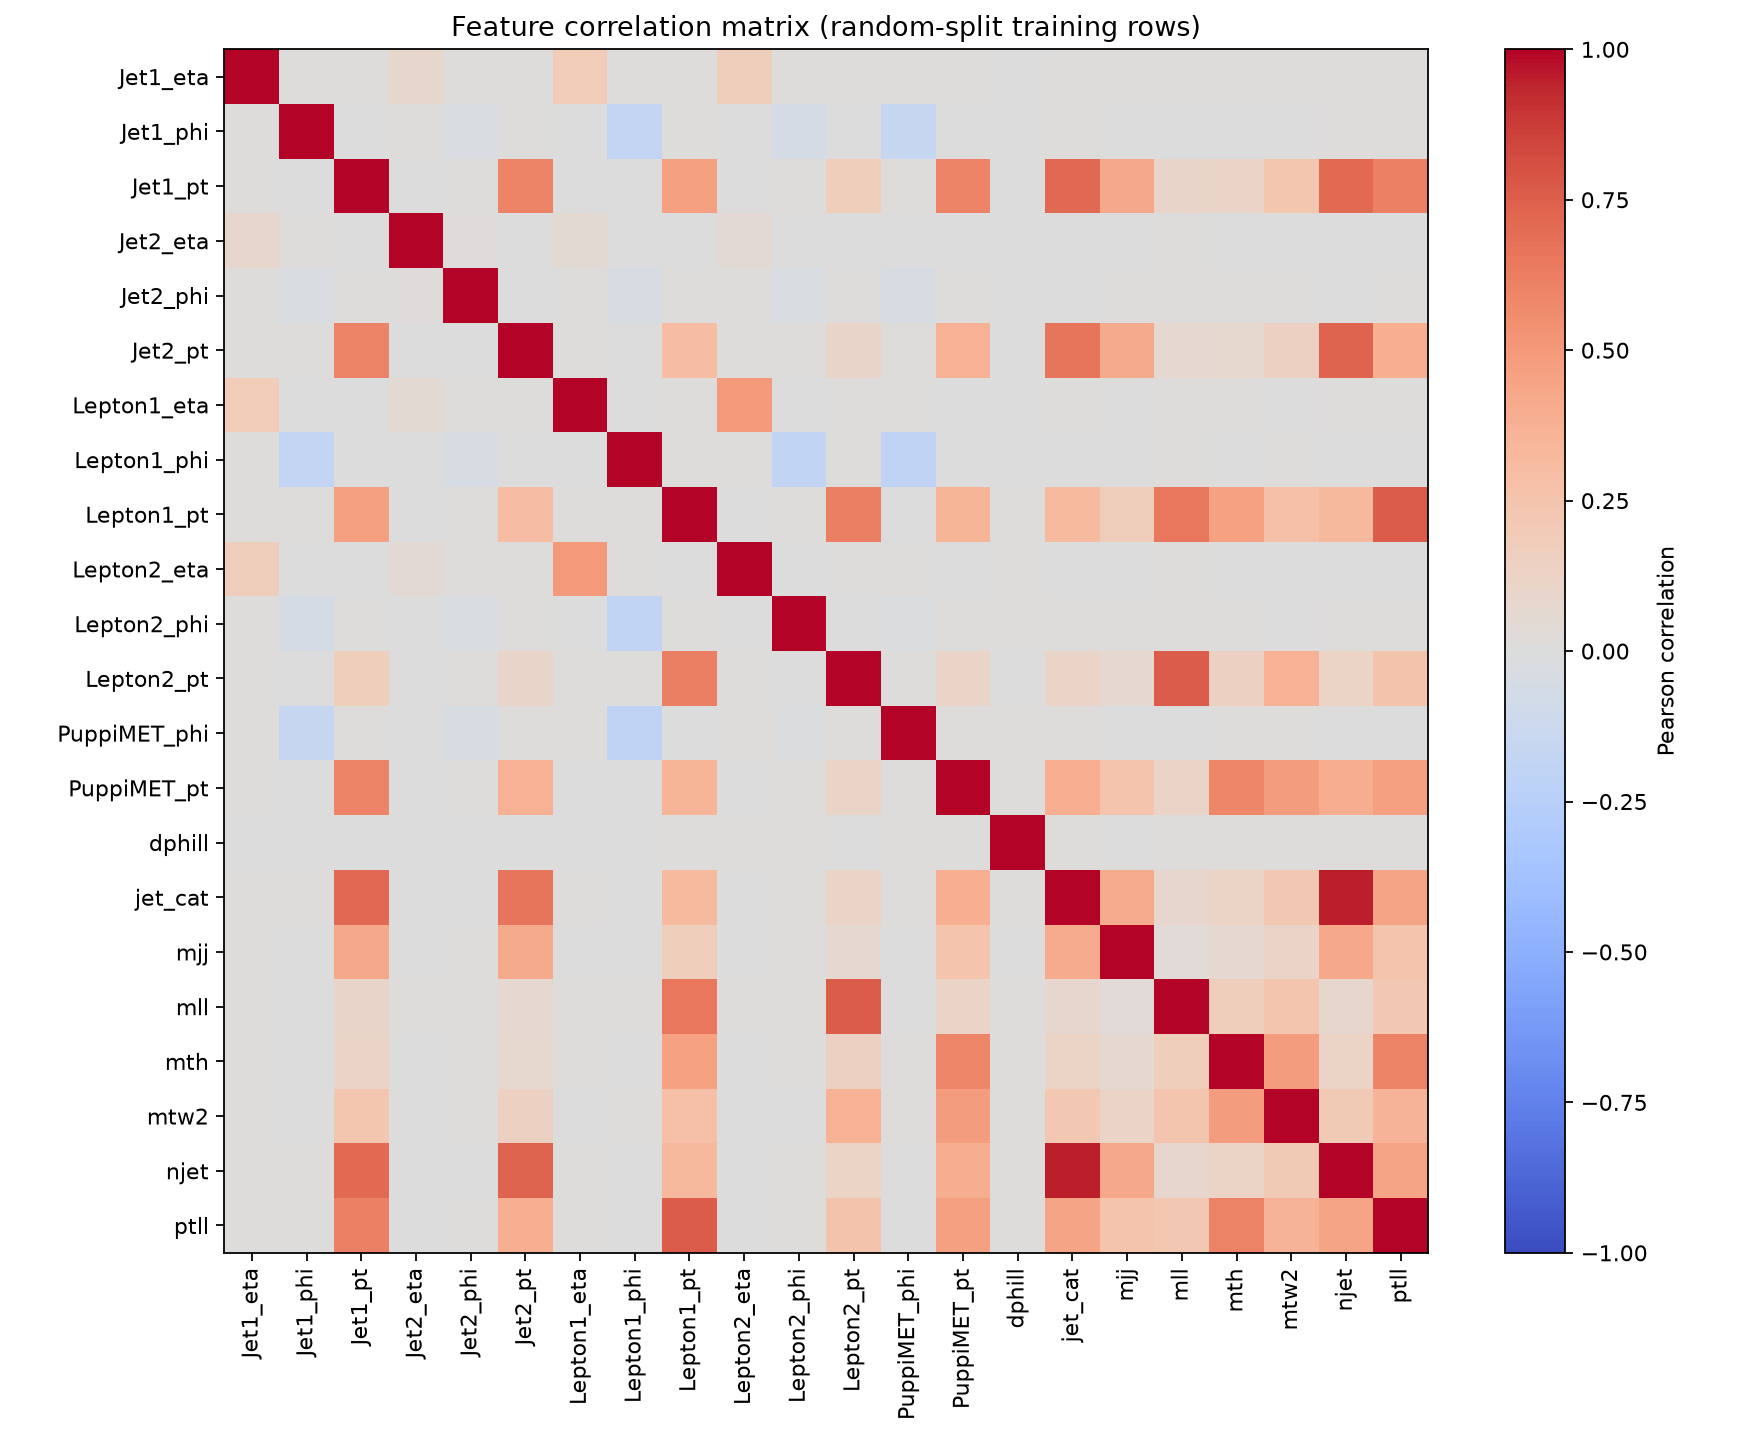

Correlation matrix shape: (22, 22) rows used: 155164


In [7]:
train_corr = np.corrcoef(X[random_train], rowvar=False)
fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(train_corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(np.arange(len(ROOT_BRANCHES)), ROOT_BRANCHES, rotation=90)
ax.set_yticks(np.arange(len(ROOT_BRANCHES)), ROOT_BRANCHES)
ax.set_title("Feature correlation matrix (random-split training rows)")
fig.colorbar(image, ax=ax, label="Pearson correlation")
fig.tight_layout()
fig.savefig(OUT_DIR / "training_feature_correlation.png", dpi=160)
display(Image(filename=str(OUT_DIR / "training_feature_correlation.png")))
plt.close(fig)
print("Correlation matrix shape:", train_corr.shape, "rows used:", len(random_train))


In [8]:
benchmark_rows=[]
binary_candidate_scores={}
fit_started=time.perf_counter(); fit_index=0
for split_name,(train_idx,val_idx) in SPLITS.items():
    for task,y_all in [("multiclass",y_multi),("binary",y_binary)]:
        y_train,y_val=y_all[train_idx],y_all[val_idx]
        for feature_set,columns in FEATURE_SETS.items():
            col_idx=[IDX[c] for c in columns]
            X_train,X_val=X[train_idx][:,col_idx],X[val_idx][:,col_idx]
            for model_id,(family,params) in MODEL_SPECS.items():
                if feature_set != "full_22" and (model_id != "hist_gradient_boosting" or task != "binary"):
                    continue
                fit_index+=1; pipe=make_pipeline(model_id)
                sample_weight=compute_sample_weight(class_weight="balanced",y=y_train)
                with threadpool_limits(limits=1):
                    pipe.fit(X_train,y_train,model__sample_weight=sample_weight)
                    p_train=pipe.predict_proba(X_train);p_val=pipe.predict_proba(X_val)
                train_metrics=metric_values(y_train,p_train,task);val_metrics=metric_values(y_val,p_val,task)
                if feature_set=="full_22" and task=="binary" and split_name=="random_stratified_80_20":
                    binary_candidate_scores[model_id]={"y_train":y_train.copy(),"train_score":p_train[:,1].copy(),
                                                       "y_validation":y_val.copy(),"validation_score":p_val[:,1].copy()}
                if feature_set=="full_22" and task=="binary":
                    ci=bootstrap_ci(y_val,p_val,task,BOOTSTRAP_SEED+fit_index,100)
                    n_bootstrap=100
                else:
                    ci={}
                    n_bootstrap=0
                benchmark_rows.append({"task":task,"split":split_name,"model":model_id,"feature_set":feature_set,
                    "n_features":len(columns),"n_train":len(train_idx),"n_validation":len(val_idx),
                    "train_metrics":train_metrics,"validation_metrics":val_metrics,"validation_95pct_row_bootstrap_ci":ci,
                    "bootstrap_replicates":n_bootstrap,"feature_columns":columns})
                print(f"{fit_index:02d}/11 {task:9s} {split_name:27s} {model_id:24s} {feature_set:31s} "
                      f"val balanced acc={val_metrics['balanced_accuracy']:.4f}")
print("Completed",len(benchmark_rows),"fits in",round(time.perf_counter()-fit_started,1),"seconds")
with (OUT_DIR/"model_comparison_metrics.json").open("w") as f:
    json.dump({"seed":SEED,"bootstrap_seed":BOOTSTRAP_SEED,"label_mapping":{str(i):c for i,c in enumerate(CLASSES)},
               "binary_positive_label":"Higgs filename label","splits":{k:{"n_train":len(v[0]),"n_validation":len(v[1])} for k,v in SPLITS.items()},
               "models":MODEL_SPECS,"feature_sets":FEATURE_SETS,"results":benchmark_rows,
               "uncertainty":"100 stratified validation-row bootstrap replicates for binary full-feature fits; multiclass and ablation metrics are point estimates; no event/source grouping available"},f,indent=2)
flat=[]
for r in benchmark_rows:
    flat.append({"task":r["task"],"split":r["split"],"model":r["model"],"feature_set":r["feature_set"],"n_features":r["n_features"],
      "accuracy":r["validation_metrics"]["accuracy"],"balanced_accuracy":r["validation_metrics"]["balanced_accuracy"],
      "roc_auc":r["validation_metrics"].get("roc_auc",r["validation_metrics"].get("macro_ovr_roc_auc")),
      "average_precision":r["validation_metrics"].get("average_precision",r["validation_metrics"].get("macro_average_precision")),
      "ci_roc_auc_low":r["validation_95pct_row_bootstrap_ci"].get("roc_auc",r["validation_95pct_row_bootstrap_ci"].get("macro_ovr_roc_auc",[float("nan"),float("nan")]))[0],
      "ci_roc_auc_high":r["validation_95pct_row_bootstrap_ci"].get("roc_auc",r["validation_95pct_row_bootstrap_ci"].get("macro_ovr_roc_auc",[float("nan"),float("nan")]))[1],
      "ci_average_precision_low":r["validation_95pct_row_bootstrap_ci"].get("average_precision",r["validation_95pct_row_bootstrap_ci"].get("macro_average_precision",[float("nan"),float("nan")]))[0],
      "ci_average_precision_high":r["validation_95pct_row_bootstrap_ci"].get("average_precision",r["validation_95pct_row_bootstrap_ci"].get("macro_average_precision",[float("nan"),float("nan")]))[1]})
with (OUT_DIR/"model_comparison_metrics.csv").open("w",newline="") as f:
    w=csv.DictWriter(f,fieldnames=list(flat[0]));w.writeheader();w.writerows(flat)

01/11 multiclass random_stratified_80_20     logistic_regression      full_22                         val balanced acc=0.6973


02/11 multiclass random_stratified_80_20     shallow_decision_tree    full_22                         val balanced acc=0.6539


03/11 multiclass random_stratified_80_20     random_forest            full_22                         val balanced acc=0.7193


04/11 multiclass random_stratified_80_20     hist_gradient_boosting   full_22                         val balanced acc=0.7248


05/11 binary    random_stratified_80_20     hist_gradient_boosting   lepton_met_dilepton_only        val balanced acc=0.8347


...

07/11 binary    random_stratified_80_20     shallow_decision_tree    full_22                         val balanced acc=0.8185


08/11 binary    random_stratified_80_20     random_forest            full_22                         val balanced acc=0.8346


09/11 binary    random_stratified_80_20     hist_gradient_boosting   full_22                         val balanced acc=0.8364


10/11 binary    random_stratified_80_20     hist_gradient_boosting   full_without_njet_and_jet_cat   val balanced acc=0.8364


11/11 binary    random_stratified_80_20     hist_gradient_boosting   full_without_jet_kinematics     val balanced acc=0.8337
Completed 11 fits in 226.3 seconds


## 7. Binary validation results

The ROC and precision-recall curves compare the four full-feature models on the same validation rows. AUC summarizes ranking across thresholds; average precision summarizes the positive-class precision-recall tradeoff. The confusion matrix and training-versus-validation score check use the HistGradientBoosting candidate at a fixed 0.5 threshold. These are validation results, not an independent test.


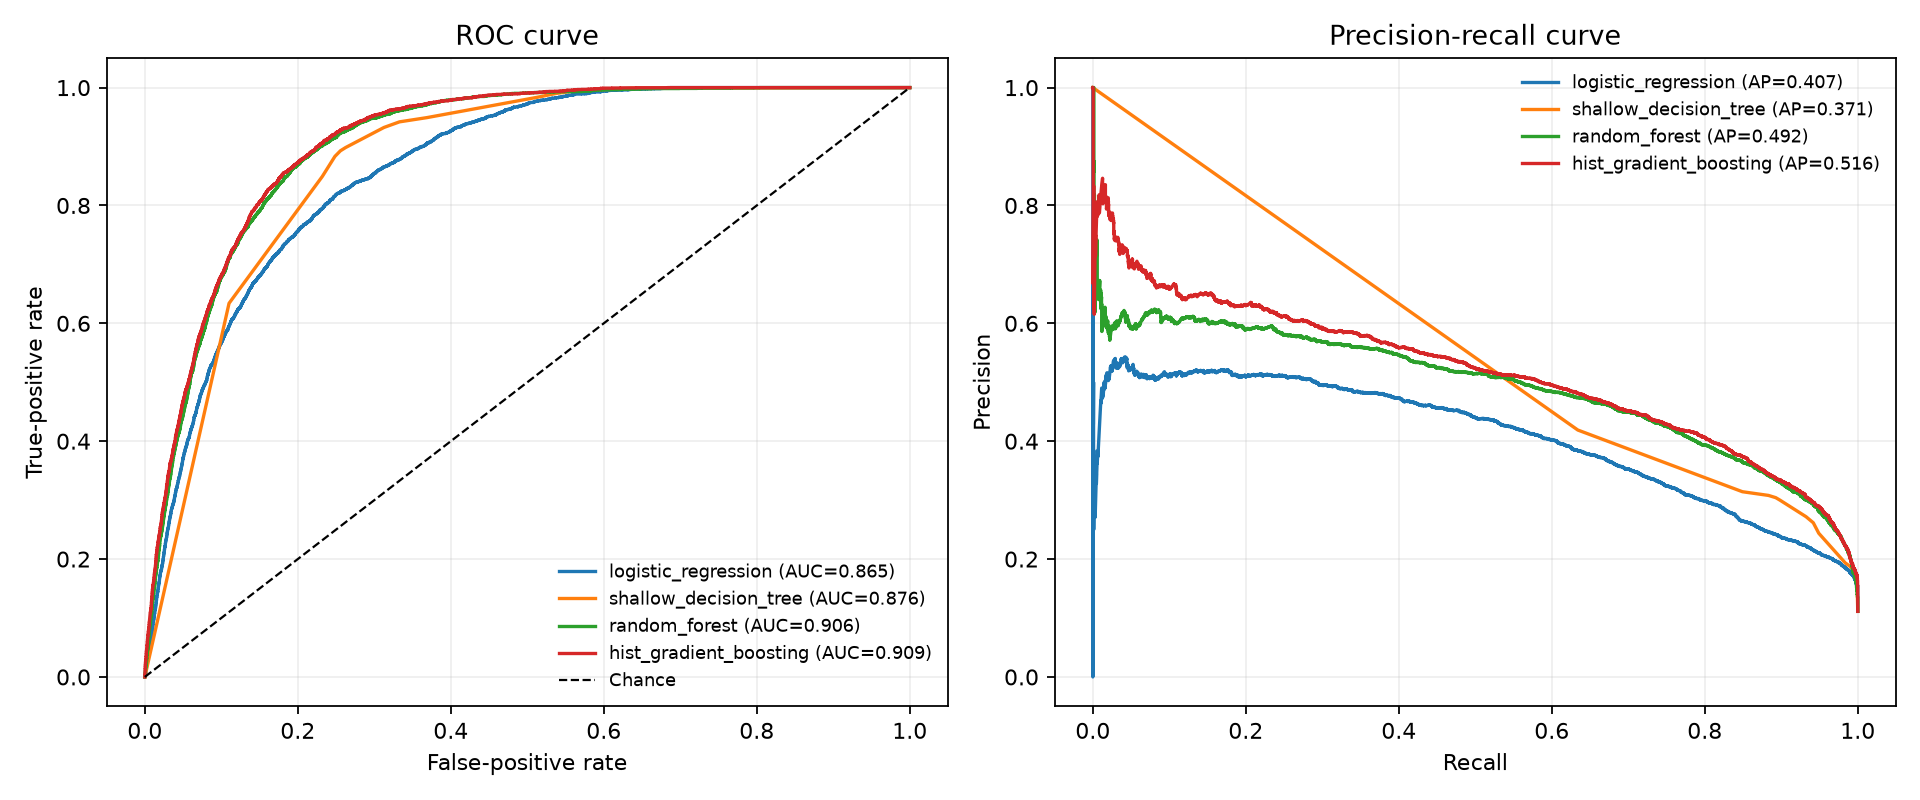

Illustrative model: hist_gradient_boosting ; positive label: Higgs filename label; threshold: 0.5
Validation ROC AUC: 0.9093457388811255
Validation average precision: 0.5160331587932434
Validation accuracy: 0.7999845328933801
Validation precision: 0.34450668594145284
Validation recall: 0.8832522585128562
Validation F1: 0.4956776080597985
Validation confusion matrix [background, Higgs]:
 [[27220  7255]
 [  504  3813]]


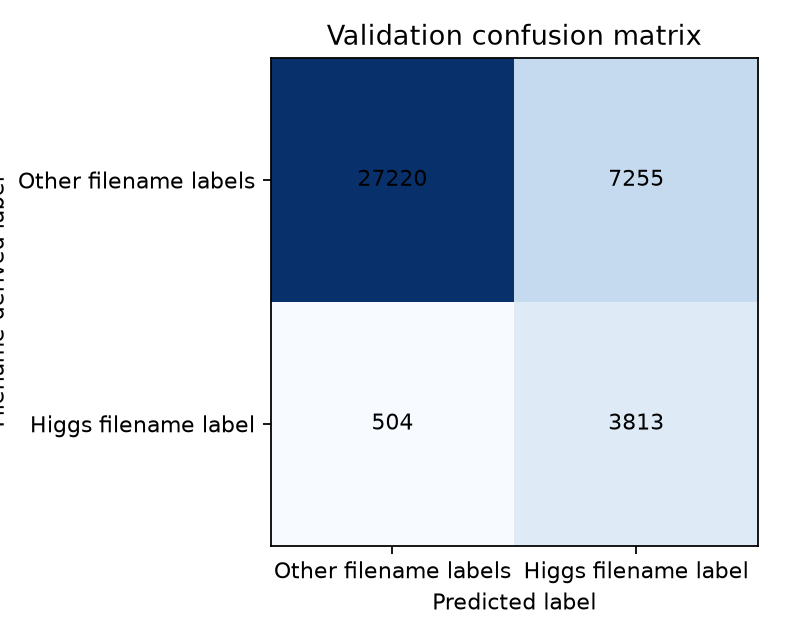

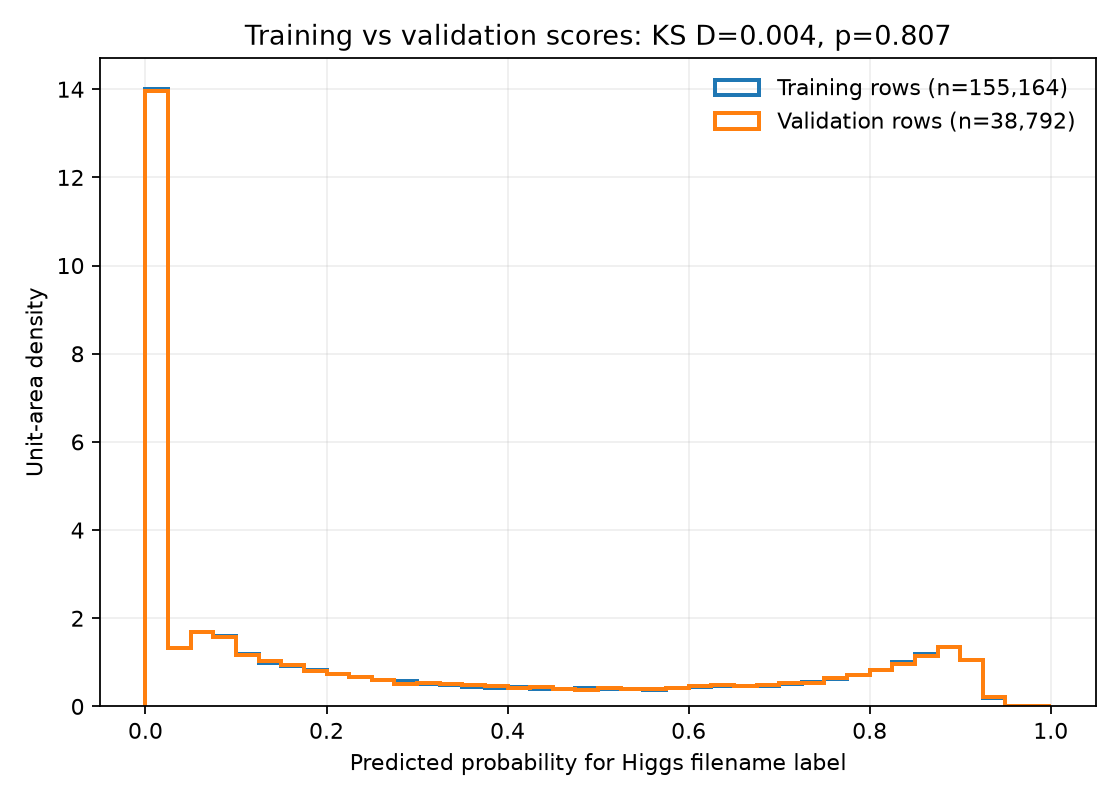

Training-vs-validation two-sample KS statistic: 0.003627441411932414
Training-vs-validation two-sample KS p-value: 0.8073835007705467
This validation-based diagnostic is not an independent test; a nonsignificant KS result would not prove absence of overtraining.


In [9]:
binary_rows=[r for r in benchmark_rows if r["task"]=="binary" and r["split"]=="random_stratified_80_20" and r["feature_set"]=="full_22"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for row in binary_rows:
    scores=binary_candidate_scores[row["model"]]["validation_score"]
    labels=binary_candidate_scores[row["model"]]["y_validation"]
    fpr,tpr,_=roc_curve(labels,scores)
    auc=roc_auc_score(labels,scores)
    axes[0].plot(fpr,tpr,label=f"{row['model']} (AUC={auc:.3f})")
    precision,recall,_=precision_recall_curve(labels,scores)
    ap=average_precision_score(labels,scores)
    axes[1].plot(recall,precision,label=f"{row['model']} (AP={ap:.3f})")
axes[0].plot([0,1],[0,1],"k--",linewidth=1,label="Chance")
axes[0].set(xlabel="False-positive rate",ylabel="True-positive rate",title="ROC curve")
axes[1].set(xlabel="Recall",ylabel="Precision",title="Precision-recall curve")
for ax in axes:
    ax.grid(alpha=.2);ax.legend(frameon=False,fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / "binary_validation_roc_pr.png",dpi=160)
display(Image(filename=str(OUT_DIR / "binary_validation_roc_pr.png")));plt.close(fig)

chosen_model="hist_gradient_boosting"
chosen=binary_candidate_scores[chosen_model]
val_score=chosen["validation_score"]
y_val=chosen["y_validation"]
y_pred=(val_score>=0.5).astype(int)
cm=confusion_matrix(y_val,y_pred,labels=[0,1])
print("Illustrative model:",chosen_model,"; positive label: Higgs filename label; threshold: 0.5")
print("Validation ROC AUC:",roc_auc_score(y_val,val_score))
print("Validation average precision:",average_precision_score(y_val,val_score))
print("Validation accuracy:",accuracy_score(y_val,y_pred))
print("Validation precision:",precision_score(y_val,y_pred,zero_division=0))
print("Validation recall:",recall_score(y_val,y_pred,zero_division=0))
print("Validation F1:",f1_score(y_val,y_pred,zero_division=0))
print("Validation confusion matrix [background, Higgs]:\n",cm)

display_labels=["Other filename labels","Higgs filename label"]
fig,ax=plt.subplots(figsize=(5,4))
ax.imshow(cm,cmap="Blues")
ax.set(xticks=[0,1],yticks=[0,1],xticklabels=display_labels,yticklabels=display_labels,
       xlabel="Predicted label",ylabel="Filename-derived label",title="Validation confusion matrix")
for (i,j),value in np.ndenumerate(cm): ax.text(j,i,str(value),ha="center",va="center",color="black")
fig.tight_layout();fig.savefig(OUT_DIR / "binary_validation_confusion_matrix.png",dpi=160);display(Image(filename=str(OUT_DIR / "binary_validation_confusion_matrix.png")));plt.close(fig)

train_score=chosen["train_score"]
ks_result=ks_2samp(train_score,val_score,alternative="two-sided",method="auto")
score_bins=np.linspace(0,1,41)
fig,ax=plt.subplots(figsize=(7,5))
ax.hist(train_score,bins=score_bins,density=True,histtype="step",linewidth=1.8,label=f"Training rows (n={len(train_score):,})")
ax.hist(val_score,bins=score_bins,density=True,histtype="step",linewidth=1.8,label=f"Validation rows (n={len(val_score):,})")
ax.set(xlabel="Predicted probability for Higgs filename label",ylabel="Unit-area density",
       title=f"Training vs validation scores: KS D={ks_result.statistic:.3f}, p={ks_result.pvalue:.3g}")
ax.grid(alpha=.2);ax.legend(frameon=False)
fig.tight_layout();fig.savefig(OUT_DIR / "binary_score_overtraining_check.png",dpi=160);display(Image(filename=str(OUT_DIR / "binary_score_overtraining_check.png")));plt.close(fig)
print("Training-vs-validation two-sample KS statistic:",ks_result.statistic)
print("Training-vs-validation two-sample KS p-value:",ks_result.pvalue)
print("This validation-based diagnostic is not an independent test; a nonsignificant KS result would not prove absence of overtraining.")


## 8. Reproducibility checks and model comparison

The notebook displays the regenerated model metrics, feature comparisons and plots below. It checks the full-feature central metrics against reference values embedded here, so the comparison works without separate audit files. It also recalculates the feature residuals and, when canonical tables are present, the feature-match counts.


Full-feature metrics agree with embedded reference values: True maximum difference: 1.5889476628894172e-07
Feature residual medians agree with embedded reference values: True
Canonical overlap comparison: PASS


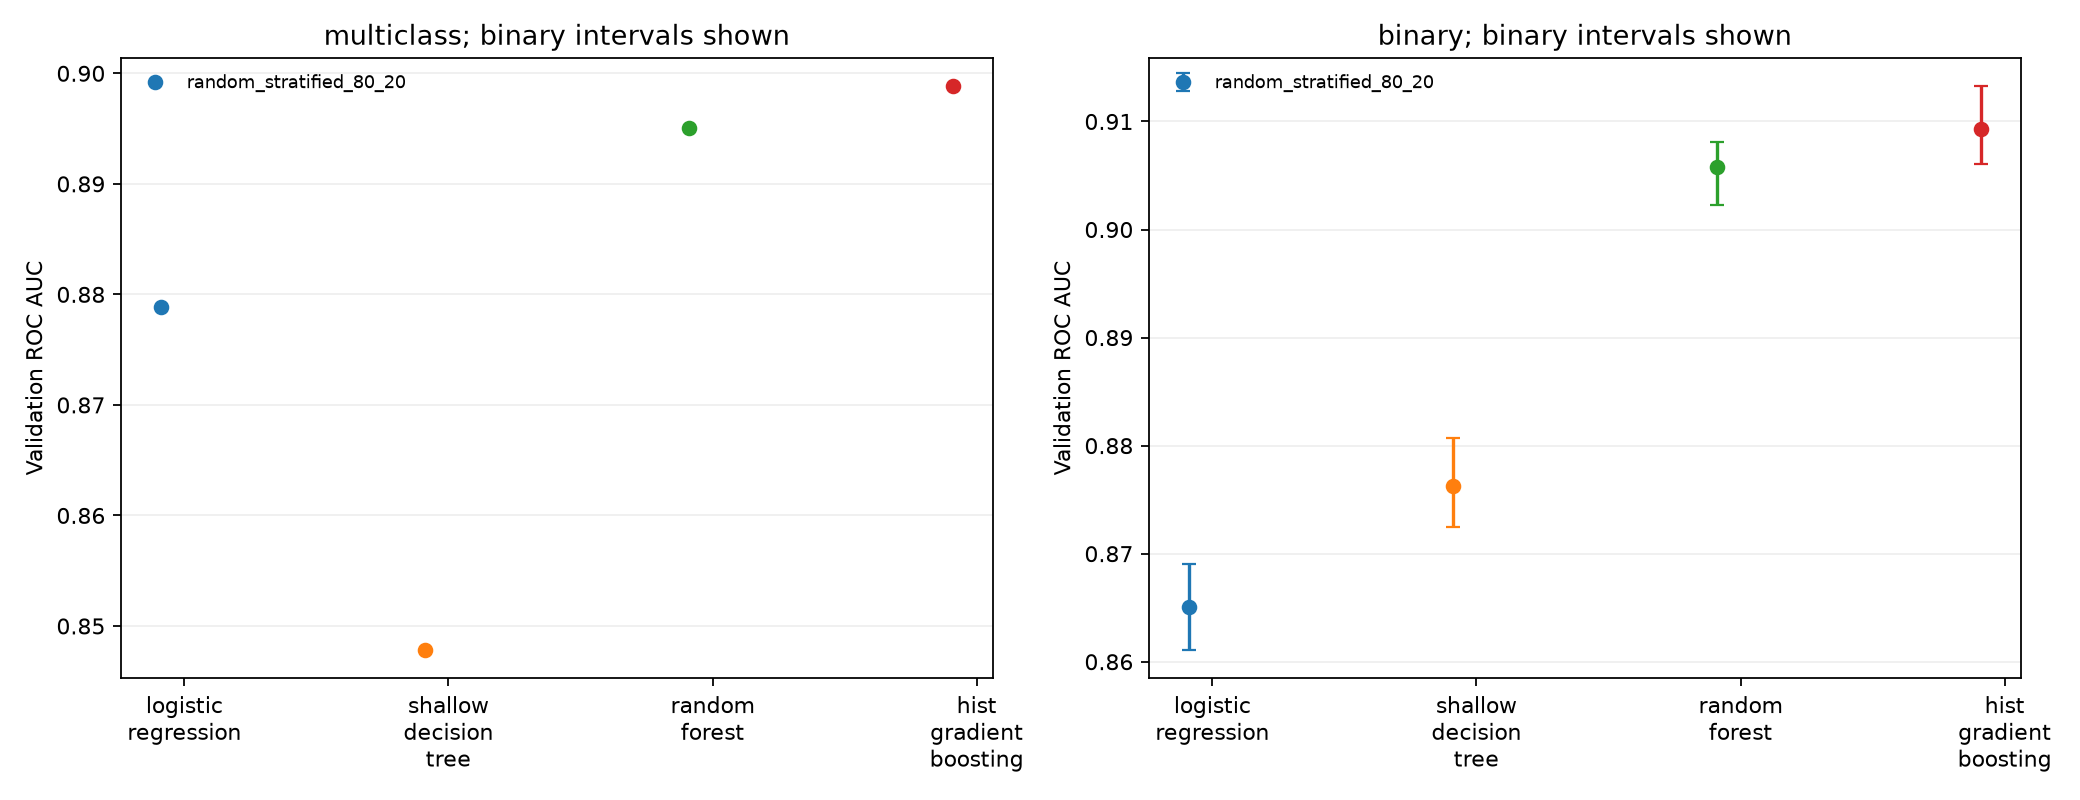

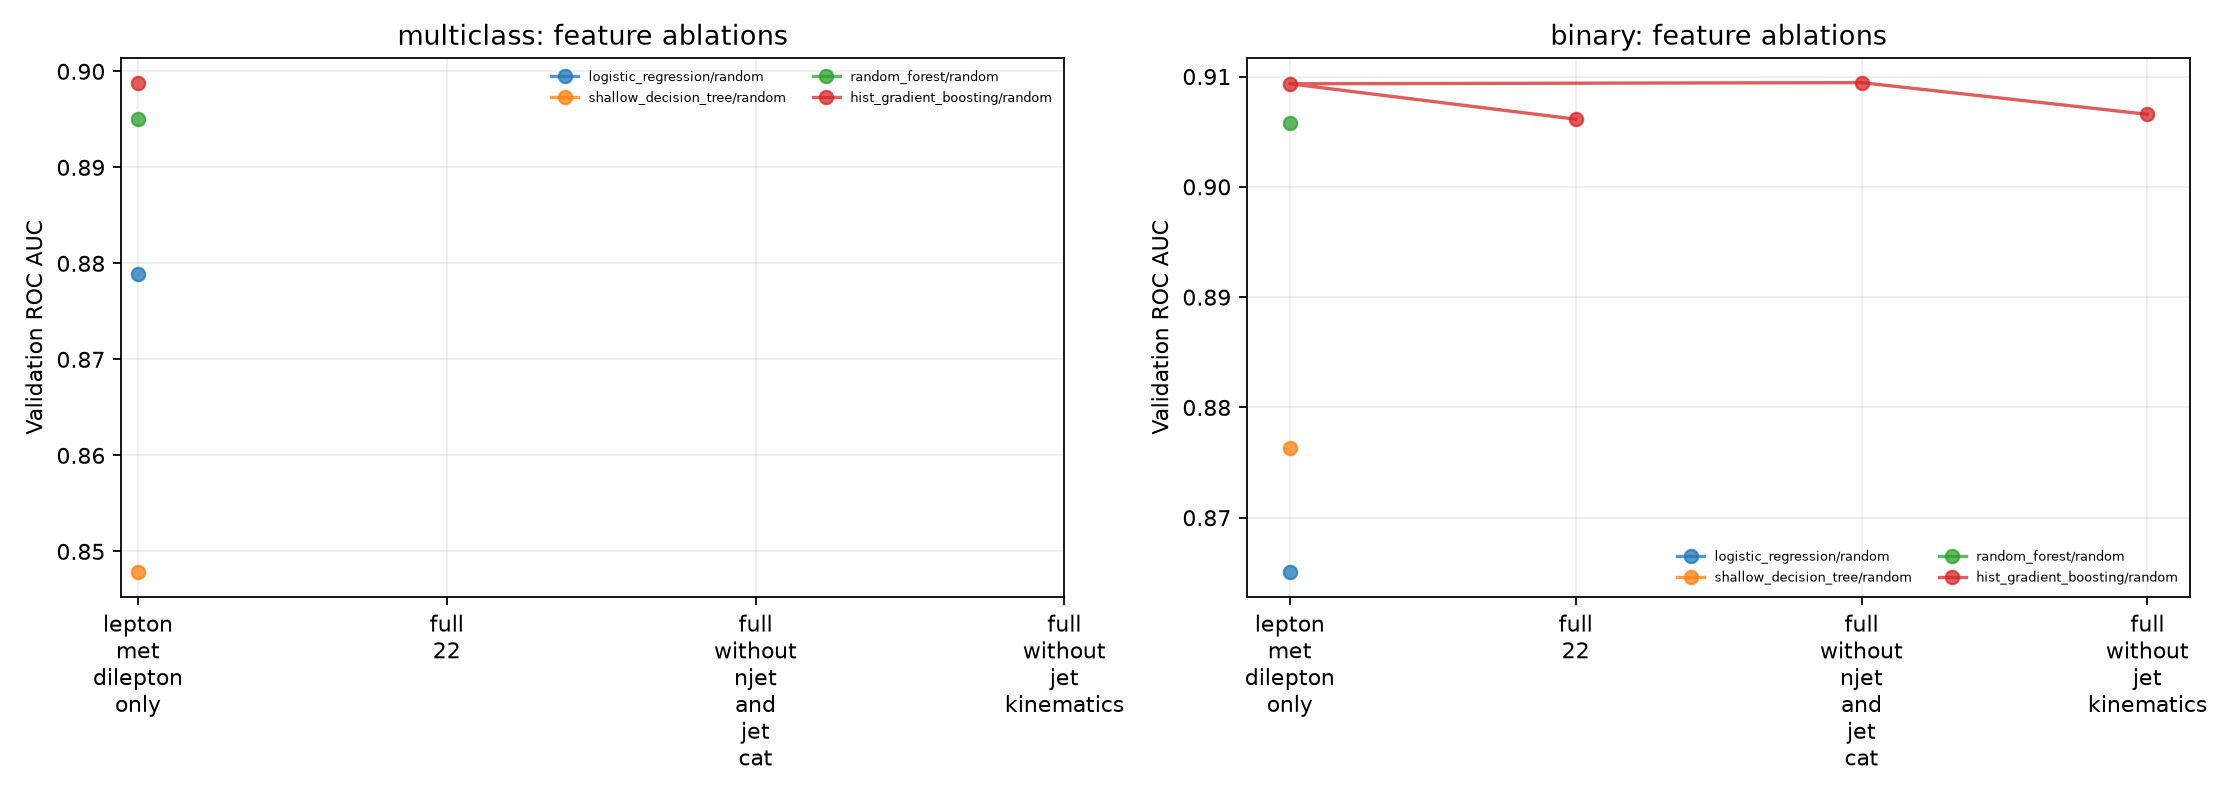

Reconciliation outputs, plots, and model metrics written to /Users/falcon/Documents/docs/hsf-india-bvcoe-2026/outputs/mentor_workflow/phase4_20261015_om_rishabh_v1


Task,Split,Model,Features,Accuracy,Balanced accuracy,ROC AUC,Average precision,ROC AUC 95% CI
multiclass,random_stratified_80_20,logistic_regression,full_22,0.609,0.697,0.879,0.631,—
multiclass,random_stratified_80_20,shallow_decision_tree,full_22,0.558,0.654,0.848,0.546,—
multiclass,random_stratified_80_20,random_forest,full_22,0.629,0.719,0.895,0.660,—
multiclass,random_stratified_80_20,hist_gradient_boosting,full_22,0.640,0.725,0.899,0.677,—
binary,random_stratified_80_20,logistic_regression,full_22,0.749,0.783,0.865,0.407,"[0.861, 0.869]"
binary,random_stratified_80_20,shallow_decision_tree,full_22,0.761,0.819,0.876,0.371,"[0.872, 0.881]"
binary,random_stratified_80_20,random_forest,full_22,0.808,0.835,0.906,0.492,"[0.902, 0.908]"
binary,random_stratified_80_20,hist_gradient_boosting,full_22,0.800,0.836,0.909,0.516,"[0.906, 0.913]"


The output table contains the 11 declared full-feature and ablation fits.


Task,Split,Model,Features,Accuracy,Balanced accuracy,ROC AUC,Average precision,ROC AUC 95% CI
multiclass,random_stratified_80_20,logistic_regression,full_22,0.609,0.697,0.879,0.631,—
multiclass,random_stratified_80_20,shallow_decision_tree,full_22,0.558,0.654,0.848,0.546,—
multiclass,random_stratified_80_20,random_forest,full_22,0.629,0.719,0.895,0.660,—
multiclass,random_stratified_80_20,hist_gradient_boosting,full_22,0.640,0.725,0.899,0.677,—
binary,random_stratified_80_20,hist_gradient_boosting,lepton_met_dilepton_only,0.795,0.835,0.906,0.495,—
binary,random_stratified_80_20,logistic_regression,full_22,0.749,0.783,0.865,0.407,"[0.861, 0.869]"
binary,random_stratified_80_20,shallow_decision_tree,full_22,0.761,0.819,0.876,0.371,"[0.872, 0.881]"
binary,random_stratified_80_20,random_forest,full_22,0.808,0.835,0.906,0.492,"[0.902, 0.908]"
binary,random_stratified_80_20,hist_gradient_boosting,full_22,0.800,0.836,0.909,0.516,"[0.906, 0.913]"
binary,random_stratified_80_20,hist_gradient_boosting,full_without_njet_and_jet_cat,0.800,0.836,0.909,0.516,—


In [10]:
# Embedded reference values keep this check independent of local audit files.
PHASE2_REFERENCE = {'binary|hist_gradient_boosting|contiguous_first80_tail20': {'accuracy': 0.8035212538344547,
                                                             'average_precision': 0.5146475068886037,
                                                             'balanced_accuracy': 0.8397120342188875,
                                                             'roc_auc': 0.9098068422939735},
 'binary|hist_gradient_boosting|random_stratified_80_20': {'accuracy': 0.7999845328933801,
                                                           'average_precision': 0.5160331587932434,
                                                           'balanced_accuracy': 0.8364049544921062,
                                                           'roc_auc': 0.9093457388811255},
 'binary|logistic_regression|contiguous_first80_tail20': {'accuracy': 0.7491557755265125,
                                                          'average_precision': 0.4043111944119163,
                                                          'balanced_accuracy': 0.7777168571044094,
                                                          'roc_auc': 0.8619242714171006},
 'binary|logistic_regression|random_stratified_80_20': {'accuracy': 0.7488399670035059,
                                                        'average_precision': 0.4069353191144965,
                                                        'balanced_accuracy': 0.782604956743018,
                                                        'roc_auc': 0.8650485902992754},
 'binary|random_forest|contiguous_first80_tail20': {'accuracy': 0.8104297167014668,
                                                    'average_precision': 0.491871406693028,
                                                    'balanced_accuracy': 0.8357972846486111,
                                                    'roc_auc': 0.9048852924258167},
 'binary|random_forest|random_stratified_80_20': {'accuracy': 0.8080789853578058,
                                                  'average_precision': 0.49178830966905906,
                                                  'balanced_accuracy': 0.8345759508884635,
                                                  'roc_auc': 0.9057847997267997},
 'binary|shallow_decision_tree|contiguous_first80_tail20': {'accuracy': 0.7727682829376434,
                                                            'average_precision': 0.3727207496638365,
                                                            'balanced_accuracy': 0.8141020400248622,
                                                            'roc_auc': 0.8771638731578232},
 'binary|shallow_decision_tree|random_stratified_80_20': {'accuracy': 0.7608269746339451,
                                                          'average_precision': 0.3713694130104747,
                                                          'balanced_accuracy': 0.8185285319032316,
                                                          'roc_auc': 0.8763022087660249},
 'multiclass|hist_gradient_boosting|contiguous_first80_tail20': {'accuracy': 0.6427963807903487,
                                                                 'balanced_accuracy': 0.7263612623445563,
                                                                 'macro_average_precision': 0.6752423252408357,
                                                                 'macro_ovr_roc_auc': 0.8990693678245414},
 'multiclass|hist_gradient_boosting|random_stratified_80_20': {'accuracy': 0.6400546504433904,
                                                               'balanced_accuracy': 0.7247513692044005,
                                                               'macro_average_precision': 0.6770794627191387,
                                                               'macro_ovr_roc_auc': 0.898824628978206},
 'multiclass|logistic_regression|contiguous_first80_tail20': {'accuracy': 0.6105225169489341,
                                                              'balanced_accuracy': 0.6945458306031639,
                                                              'macro_average_precision': 0.6298886602184753,
                                                              'macro_ovr_roc_auc': 0.8782696916057273},
 'multiclass|logistic_regression|random_stratified_80_20': {'accuracy': 0.6091462157145803,
                                                            'balanced_accuracy': 0.6973443521838671,
                                                            'macro_average_precision': 0.6308463382157781,
                                                            'macro_ovr_roc_auc': 0.8788894693298335},
 'multiclass|random_forest|contiguous_first80_tail20': {'accuracy': 0.6288763436702498,
                                                        'balanced_accuracy': 0.7188739814221546,
                                                        'macro_average_precision': 0.6618040329564352,
                                                        'macro_ovr_roc_auc': 0.8951857126921182},
 'multiclass|random_forest|random_stratified_80_20': {'accuracy': 0.6285058775005156,
                                                      'balanced_accuracy': 0.7192653912451021,
                                                      'macro_average_precision': 0.6598144126765686,
                                                      'macro_ovr_roc_auc': 0.8950555187658509},
 'multiclass|shallow_decision_tree|contiguous_first80_tail20': {'accuracy': 0.5688912948212307,
                                                                'balanced_accuracy': 0.6566051885674846,
                                                                'macro_average_precision': 0.5462483390688786,
                                                                'macro_ovr_roc_auc': 0.847496731439637},
 'multiclass|shallow_decision_tree|random_stratified_80_20': {'accuracy': 0.5582852134460714,
                                                              'balanced_accuracy': 0.65393642741316,
                                                              'macro_average_precision': 0.5462381667342227,
                                                              'macro_ovr_roc_auc': 0.8478182640432319}}
PHASE3_FORMULA_MEDIAN_REFERENCE = {'DY|dphill': 6.357301884918343e-08,
 'DY|mth': 1.4125700085187987e-06,
 'DY|mtw2': 1.0789343107830973e-06,
 'DY|ptll': 5.822760300588925e-07,
 'Higgs|dphill': 0.0,
 'Higgs|mth': 2.9360212252527162e-06,
 'Higgs|mtw2': 1.6187518205867946e-06,
 'Higgs|ptll': 1.3089777528563218e-06,
 'Top|dphill': 6.357301884918343e-08,
 'Top|mth': 4.383645844541206e-06,
 'Top|mtw2': 2.312986154606733e-06,
 'Top|ptll': 1.7013402100474195e-06,
 'WW|dphill': 6.357301884918343e-08,
 'WW|mth': 2.888916117882445e-06,
 'WW|mtw2': 2.0830590514719916e-06,
 'WW|ptll': 1.2897439773951191e-06}
PHASE3_OVERLAP_REFERENCE = {'DY|canonical_expanded_10000_per_process_20261015_v1|DYJetsToLL_M50': [1794, 2497],
 'DY|canonical_expanded_10000_per_process_20261015_v1|continuum_WW_2l2nu': [0, 0],
 'DY|canonical_expanded_10000_per_process_20261015_v1|ggH_H_WW_2l2nu': [0, 0],
 'DY|canonical_expanded_10000_per_process_20261015_v1|single_top_tW_antitop': [0, 0],
 'DY|canonical_expanded_10000_per_process_20261015_v1|single_top_tW_top': [0, 0],
 'DY|canonical_expanded_10000_per_process_20261015_v1|ttbar_2l2nu': [0, 0],
 'DY|canonical_pilot_1000_per_process_20261015_v1|DYJetsToLL_M50': [0, 0],
 'DY|canonical_pilot_1000_per_process_20261015_v1|continuum_WW_2l2nu': [0, 0],
 'DY|canonical_pilot_1000_per_process_20261015_v1|ggH_H_WW_2l2nu': [0, 0],
 'DY|canonical_pilot_1000_per_process_20261015_v1|single_top_tW_antitop': [0, 0],
 'DY|canonical_pilot_1000_per_process_20261015_v1|single_top_tW_top': [0, 0],
 'DY|canonical_pilot_1000_per_process_20261015_v1|ttbar_2l2nu': [0, 0],
 'Higgs|canonical_expanded_10000_per_process_20261015_v1|DYJetsToLL_M50': [0, 0],
 'Higgs|canonical_expanded_10000_per_process_20261015_v1|continuum_WW_2l2nu': [0, 0],
 'Higgs|canonical_expanded_10000_per_process_20261015_v1|ggH_H_WW_2l2nu': [0, 0],
 'Higgs|canonical_expanded_10000_per_process_20261015_v1|single_top_tW_antitop': [0, 0],
 'Higgs|canonical_expanded_10000_per_process_20261015_v1|single_top_tW_top': [0, 0],
 'Higgs|canonical_expanded_10000_per_process_20261015_v1|ttbar_2l2nu': [0, 0],
 'Higgs|canonical_pilot_1000_per_process_20261015_v1|DYJetsToLL_M50': [0, 0],
 'Higgs|canonical_pilot_1000_per_process_20261015_v1|continuum_WW_2l2nu': [0, 0],
 'Higgs|canonical_pilot_1000_per_process_20261015_v1|ggH_H_WW_2l2nu': [0, 0],
 'Higgs|canonical_pilot_1000_per_process_20261015_v1|single_top_tW_antitop': [0, 0],
 'Higgs|canonical_pilot_1000_per_process_20261015_v1|single_top_tW_top': [0, 0],
 'Higgs|canonical_pilot_1000_per_process_20261015_v1|ttbar_2l2nu': [0, 0],
 'Top|canonical_expanded_10000_per_process_20261015_v1|DYJetsToLL_M50': [0, 0],
 'Top|canonical_expanded_10000_per_process_20261015_v1|continuum_WW_2l2nu': [0, 0],
 'Top|canonical_expanded_10000_per_process_20261015_v1|ggH_H_WW_2l2nu': [0, 0],
 'Top|canonical_expanded_10000_per_process_20261015_v1|single_top_tW_antitop': [984, 1528],
 'Top|canonical_expanded_10000_per_process_20261015_v1|single_top_tW_top': [1101, 1696],
 'Top|canonical_expanded_10000_per_process_20261015_v1|ttbar_2l2nu': [0, 0],
 'Top|canonical_pilot_1000_per_process_20261015_v1|DYJetsToLL_M50': [0, 0],
 'Top|canonical_pilot_1000_per_process_20261015_v1|continuum_WW_2l2nu': [0, 0],
 'Top|canonical_pilot_1000_per_process_20261015_v1|ggH_H_WW_2l2nu': [0, 0],
 'Top|canonical_pilot_1000_per_process_20261015_v1|single_top_tW_antitop': [13, 21],
 'Top|canonical_pilot_1000_per_process_20261015_v1|single_top_tW_top': [68, 105],
 'Top|canonical_pilot_1000_per_process_20261015_v1|ttbar_2l2nu': [0, 0],
 'WW|canonical_expanded_10000_per_process_20261015_v1|DYJetsToLL_M50': [0, 0],
 'WW|canonical_expanded_10000_per_process_20261015_v1|continuum_WW_2l2nu': [0, 0],
 'WW|canonical_expanded_10000_per_process_20261015_v1|ggH_H_WW_2l2nu': [0, 0],
 'WW|canonical_expanded_10000_per_process_20261015_v1|single_top_tW_antitop': [0, 0],
 'WW|canonical_expanded_10000_per_process_20261015_v1|single_top_tW_top': [0, 0],
 'WW|canonical_expanded_10000_per_process_20261015_v1|ttbar_2l2nu': [0, 0],
 'WW|canonical_pilot_1000_per_process_20261015_v1|DYJetsToLL_M50': [0, 0],
 'WW|canonical_pilot_1000_per_process_20261015_v1|continuum_WW_2l2nu': [261, 385],
 'WW|canonical_pilot_1000_per_process_20261015_v1|ggH_H_WW_2l2nu': [0, 0],
 'WW|canonical_pilot_1000_per_process_20261015_v1|single_top_tW_antitop': [0, 0],
 'WW|canonical_pilot_1000_per_process_20261015_v1|single_top_tW_top': [0, 0],
 'WW|canonical_pilot_1000_per_process_20261015_v1|ttbar_2l2nu': [0, 0]}

reconciliation=[]
for r in benchmark_rows:
    if r["feature_set"]!="full_22": continue
    key="|".join([r["task"],r["model"],r["split"]])
    old=PHASE2_REFERENCE[key]; new=r["validation_metrics"]
    for metric,before in old.items():
        after=new[metric]
        reconciliation.append({"task":r["task"],"model":r["model"],"split":r["split"],"metric":metric,
                               "reference":before,"regenerated":after,"absolute_difference":abs(before-after),
                               "within_1e-6":abs(before-after)<=1e-6})
phase2_reconciled=all(row["within_1e-6"] for row in reconciliation)
print("Full-feature metrics agree with embedded reference values:",phase2_reconciled,
      "maximum difference:",max(x["absolute_difference"] for x in reconciliation))

formula_reconciliation=[]
for row in feature_validation:
    key=f"{row['sample']}|{row['feature_or_hypothesis']}"
    if key not in PHASE3_FORMULA_MEDIAN_REFERENCE: continue
    reference=PHASE3_FORMULA_MEDIAN_REFERENCE[key]
    diff=abs(reference-row["absolute_median"])
    formula_reconciliation.append({"sample":row["sample"],"feature":row["feature_or_hypothesis"],
                                   "reference_median":reference,"regenerated_median":row["absolute_median"],
                                   "absolute_difference":diff,"within_1e-12":diff<=1e-12})
formula_reconciled=all(r["within_1e-12"] for r in formula_reconciliation)
print("Feature residual medians agree with embedded reference values:",formula_reconciled)

overlap_reconciliation=[]
if match_rows:
    for row in match_rows:
        key="|".join([row["mentor_file_label"],row["canonical_dataset"],row["canonical_process_label"]])
        if key in PHASE3_OVERLAP_REFERENCE:
            reference=PHASE3_OVERLAP_REFERENCE[key]
            observed=[row["exact_8_feature_rows"],row["approximate_8_feature_rows"]]
            overlap_reconciliation.append({"key":key,"reference":reference,"regenerated":observed,"match":reference==observed})
    overlap_reconciled=(len(overlap_reconciliation)==len(match_rows) and all(r["match"] for r in overlap_reconciliation))
else:
    overlap_reconciled=None
print("Canonical overlap comparison:","not run" if overlap_reconciled is None else ("PASS" if overlap_reconciled else "DISCREPANCY"))
with (OUT_DIR/"reproducibility_reconciliation.json").open("w") as f:
    json.dump({"phase2_full_feature_metrics_all_within_1e-6":phase2_reconciled,"phase2_metrics":reconciliation,
               "phase3_formula_medians":formula_reconciliation,"phase3_canonical_overlap":overlap_reconciliation,
               "canonical_overlap_run":bool(match_rows),"test_file_event_values_read":False},f,indent=2)

# Plot AUC with bootstrap intervals for the main full-feature comparisons.
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,task in zip(axes,["multiclass","binary"]):
    for si,split in enumerate(SPLITS):
        group=[r for r in benchmark_rows if r["task"]==task and r["split"]==split and r["feature_set"]=="full_22"]
        xs=np.arange(len(group))+si*.18-.09
        for x,r in zip(xs,group):
            key="roc_auc" if task=="binary" else "macro_ovr_roc_auc"
            ci=r["validation_95pct_row_bootstrap_ci"].get(key)
            value=r["validation_metrics"][key]
            if ci:
                ax.errorbar(x,value,yerr=[[value-ci[0]],[ci[1]-value]],fmt="o",capsize=3,label=split if x==xs[0] else None)
            else:
                ax.plot(x,value,"o",label=split if x==xs[0] else None)
    ax.set_xticks(np.arange(4),[x.replace("_","\n") for x in MODEL_SPECS]);ax.set_ylabel("Validation ROC AUC")
    ax.set_title(task+"; binary intervals shown");ax.grid(axis="y",alpha=.2);ax.legend(frameon=False,fontsize=8)
fig.tight_layout();fig.savefig(OUT_DIR/"model_comparison_auc.png",dpi=160);display(Image(filename=str(OUT_DIR/"model_comparison_auc.png")));plt.close(fig)

# One-factor feature-ablation visualization: macro AUC or binary AUC.
fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,task in zip(axes,["multiclass","binary"]):
    for split in SPLITS:
        for model in MODEL_SPECS:
            rs=[r for r in benchmark_rows if r["task"]==task and r["split"]==split and r["model"]==model]
            rs=sorted(rs,key=lambda x:list(FEATURE_SETS).index(x["feature_set"]))
            metric="roc_auc" if task=="binary" else "macro_ovr_roc_auc"
            ax.plot([r["feature_set"] for r in rs],[r["validation_metrics"][metric] for r in rs],marker="o",alpha=.75,label=f"{model}/{split.split('_')[0]}")
    ax.set_xticks(range(len(FEATURE_SETS)),[x.replace("_","\n") for x in FEATURE_SETS]);ax.set_ylabel("Validation ROC AUC")
    ax.set_title(f"{task}: feature ablations");ax.grid(alpha=.2);ax.legend(frameon=False,fontsize=6,ncol=2)
fig.tight_layout();fig.savefig(OUT_DIR/"feature_ablation_auc.png",dpi=160);display(Image(filename=str(OUT_DIR/"feature_ablation_auc.png")));plt.close(fig)

print("Reconciliation outputs, plots, and model metrics written to",OUT_DIR)
from IPython.display import HTML, display
def render_metric_table(rows):
    headers=["Task","Split","Model","Features","Accuracy","Balanced accuracy","ROC AUC","Average precision","ROC AUC 95% CI"]
    body=[]
    for r in rows:
        m=r["validation_metrics"]; ci=r["validation_95pct_row_bootstrap_ci"]
        auc_key="roc_auc" if r["task"]=="binary" else "macro_ovr_roc_auc"
        ap_key="average_precision" if r["task"]=="binary" else "macro_average_precision"
        auc_ci=ci.get(auc_key)
        ci_text=f"[{auc_ci[0]:.3f}, {auc_ci[1]:.3f}]" if auc_ci else "—"
        body.append([r["task"],r["split"],r["model"],r["feature_set"],f"{m['accuracy']:.3f}",
                     f"{m['balanced_accuracy']:.3f}",f"{m[auc_key]:.3f}",f"{m[ap_key]:.3f}",ci_text])
    head="".join(f"<th>{h}</th>" for h in headers)
    body_html="".join("<tr>"+"".join(f"<td>{v}</td>" for v in row)+"</tr>" for row in body)
    return HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body_html}</tbody></table>")

main_rows=[r for r in benchmark_rows if r["feature_set"]=="full_22"]
display(render_metric_table(main_rows))
print("The output table contains the 11 declared full-feature and ablation fits.")
display(render_metric_table([r for r in benchmark_rows if r["split"]=="random_stratified_80_20"]))


## 9. Conclusion and next steps

These plots and metrics describe how filename-labelled rows separate under the chosen splits. The KS comparison checks whether the selected model's training and validation score shapes differ; it cannot establish that there is no overtraining, and validation is not an independent test set. The CMS process identities, event independence and physical normalization remain unverified. A final evaluation needs a suitable independent sample with both signal and background under a documented selection.


In [11]:
print("Model rows:",len(benchmark_rows),"(8 full-feature fits plus 3 binary HistGradientBoosting ablations)")
print("Embedded full-feature reference comparison:","PASS" if phase2_reconciled else "DISCREPANCY")
print("Feature calculation comparison:","PASS" if formula_reconciled else "DISCREPANCY")
print("Canonical feature comparison:","not run" if overlap_reconciled is None else ("PASS" if overlap_reconciled else "DISCREPANCY"))
print("Validation KS diagnostic shown for HistGradientBoosting; it is not an independent test.")
print("Exploratory only: filename labels, no verified process identity, no physics normalization, no test-file use, no model freeze.")
assert len(benchmark_rows)==11
assert phase2_reconciled
assert formula_reconciled
assert overlap_reconciled is None or overlap_reconciled


Model rows: 11 (8 full-feature fits plus 3 binary HistGradientBoosting ablations)
Embedded full-feature reference comparison: PASS
Feature calculation comparison: PASS
Canonical feature comparison: PASS
Validation KS diagnostic shown for HistGradientBoosting; it is not an independent test.
Exploratory only: filename labels, no verified process identity, no physics normalization, no test-file use, no model freeze.
